# Detector de voz sintética em inglês: v2 (augmentation)

> **Um detector que classifica se uma voz em inglês foi gerada por IA, para alertar contra golpes de clonagem de voz e evitar que ouvintes e sistemas confiem em um áudio que finge ser uma pessoa real.**

**Objetivo desta versão:** o baseline (v1) foi ótimo na validação (EER 1,3%) e péssimo fora dela (AUC 0,211 no In-the-Wild, acusando 91% das vozes reais, e 41,6% de falso alarme no CORAA). A hipótese é que o modelo aprendeu **"gravação limpa = real"**, porque todo áudio real do treino é limpo (estúdio ou audiolivro). Aqui nós **testamos** essa hipótese e **atacamos** o problema com augmentation, mudando **uma coisa por experimento** e mantendo o resto igual ao baseline.

Este notebook contém **só a versão atual (v2)**. A v1 está arquivada em [`notebooks/versions/v1_baseline.ipynb`](notebooks/versions/v1_baseline.ipynb), e o registro de todas as versões fica em [`docs/HISTORICO_VERSOES.md`](docs/HISTORICO_VERSOES.md).

## Histórico das versões

**O que faz:** lê `results/baseline_results.csv` (v1) e `results/experiments.csv` (v2 em diante) e mostra uma linha por versão/experimento.
**Por quê:** antes de propor algo novo, todo mundo vê o que já foi tentado. O registro completo, com hipótese e conclusão de cada versão, está em [`docs/HISTORICO_VERSOES.md`](docs/HISTORICO_VERSOES.md).

Como ler: "val (média por fonte)" e "dev_shift" são os números usados para **decidir** entre versões; as colunas de teste são só para **reportar** (cada versão é avaliada no teste uma única vez). Na v1, o teste usou o recorte central de 4 s e o In-the-Wild inteiro; da v2 em diante, o teste usa janelas deslizantes e só a parte `test_final` do In-the-Wild (ver seções 3 e 7).

**Resumo do histórico** (registro completo em [`docs/HISTORICO_VERSOES.md`](docs/HISTORICO_VERSOES.md)):

| versão | o que mudou | resultado em uma frase |
|:--|:--|:--|
| v1 | baseline: CNN pequena em log-mel, sem augmentation | ótimo na validação (EER 1,3%) e péssimo fora: In-the-Wild com AUC 0,211 e 41,6% de falso alarme no CORAA |
| v2 · v1r | só a regra do checkpoint (EER média por fonte) | parecido com a v1; In-the-Wild continua invertido (dev_shift AUC 0,325) |
| v2 · v2a | + volume (RMS e ganho), um controle | validação igual; dev_shift sobe para 0,386, mas é um controle: dá o tamanho do acaso entre execuções |
| v2 · v2b | + ruído, banda de telefone e mu-law | robusto às degradações que viu, mas o dev_shift não melhora em relação ao v2a (0,389) e a validação piora um pouco; a hipótese "limpo = real" **não se confirmou** |

In [1]:
from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display


def _pct(v):
    return "—" if pd.isna(v) else f"{100 * v:.1f}%"


def _auc(v):
    return "—" if pd.isna(v) else f"{v:.3f}"


hist_linhas = []
b = pd.read_csv("results/baseline_results.csv", index_col=0)
hist_linhas.append({
    "versão": "v1 (baseline)", "teste avaliado com": "recorte central",
    "EER val (global)": _pct(b.loc["validação", "EER"]),
    # média das EER por fonte da validação, da seção 7.3 do notebook v1: (0,26% + 7,82% + 32,69%) / 3
    "EER val (média por fonte)": _pct((0.002641 + 0.078220 + 0.326868) / 3),
    "dev_shift AUC": "—", "dev_shift EER": "—",
    "In-the-Wild AUC": _auc(b.loc["in_the_wild", "AUC"]) + " (banco inteiro)",
    "LlamaPartialSpoof AUC": _auc(b.loc["llamapartialspoof", "AUC"]),
    "BRSpeech-DF AUC": _auc(b.loc["brspeech_df", "AUC"]),
    "CORAA falso alarme": _pct(b.loc["coraa", "falso alarme"]),
    "notebook": "notebooks/versions/v1_baseline.ipynb"})

if Path("results/experiments.csv").exists():
    e = pd.read_csv("results/experiments.csv")
    for exp, g in e.groupby("experimento", sort=False):
        def pega(conjunto, banco, col, modo):
            s = g[(g.conjunto == conjunto) & (g.banco == banco) & (g["avaliação"] == modo)][col]
            return s.iloc[0] if len(s) else float("nan")
        hist_linhas.append({
            "versão": f"{g['versão'].iloc[0]} · {exp}", "teste avaliado com": "janelas de 4 s (passo 2 s)",
            "EER val (global)": _pct(pega("validação", "todas as fontes", "EER", "central")),
            "EER val (média por fonte)": _pct(g["EER média por fonte val (checkpoint)"].iloc[0]),
            "dev_shift AUC": _auc(pega("dev_shift", "in_the_wild", "AUC", "janelas")),
            "dev_shift EER": _pct(pega("dev_shift", "in_the_wild", "EER", "janelas")),
            "In-the-Wild AUC": _auc(pega("test_final", "in_the_wild", "AUC", "janelas")) + " (test_final)",
            "LlamaPartialSpoof AUC": _auc(pega("test_final", "llamapartialspoof", "AUC", "janelas")),
            "BRSpeech-DF AUC": _auc(pega("test_final", "brspeech_df", "AUC", "janelas")),
            "CORAA falso alarme": _pct(pega("test_final", "coraa", "falso alarme", "janelas")),
            "notebook": "notebook.ipynb (versão atual)"})
else:
    print("results/experiments.csv ainda não existe: rode a seção 7 para gerar.")
display(Markdown(pd.DataFrame(hist_linhas).to_markdown(index=False)))

| versão        | teste avaliado com         | EER val (global)   | EER val (média por fonte)   | dev_shift AUC   | dev_shift EER   | In-the-Wild AUC       |   LlamaPartialSpoof AUC |   BRSpeech-DF AUC | CORAA falso alarme   | notebook                             |
|:--------------|:---------------------------|:-------------------|:----------------------------|:----------------|:----------------|:----------------------|------------------------:|------------------:|:---------------------|:-------------------------------------|
| v1 (baseline) | recorte central            | 1.3%               | 13.6%                       | —               | —               | 0.211 (banco inteiro) |                   0.563 |             0.766 | 41.6%                | notebooks/versions/v1_baseline.ipynb |
| v2 · v1r      | janelas de 4 s (passo 2 s) | 1.4%               | 12.6%                       | 0.325           | 63.7%           | 0.262 (test_final)    |                   0.625 |             0.776 | 34.9%                | notebook.ipynb (versão atual)        |
| v2 · v2a      | janelas de 4 s (passo 2 s) | 1.1%               | 13.0%                       | 0.386           | 58.1%           | 0.354 (test_final)    |                   0.595 |             0.801 | 24.3%                | notebook.ipynb (versão atual)        |
| v2 · v2b      | janelas de 4 s (passo 2 s) | 2.0%               | 14.3%                       | 0.389           | 57.0%           | 0.336 (test_final)    |                   0.646 |             0.779 | 29.8%                | notebook.ipynb (versão atual)        |

## 1. Introdução

**O diagnóstico da v1.** Três sinais apontam para o mesmo problema:
1. No **In-the-Wild** (áudios de internet), a AUC foi 0,211: o modelo ordena **ao contrário**, dando nota de fake mais alta aos reais.
2. No **CORAA** (só vozes reais em pt-BR, gravações de entrevistas e aulas), **41,6%** dos reais foram acusados.
3. No **ASVspoof 2021 DF**, os mesmos tipos de ataque do treino, só que com compressão de codec, derrubaram a AUC de 0,97 para 0,69.

A hipótese: no treino, **todo real é gravação limpa** (VCTK em estúdio e LibriSpeech de audiolivro), então "som limpo" virou sinônimo de "real", e qualquer ruído, compressão ou microfone ruim empurra o áudio para "fake".

**Como vamos testar e atacar a hipótese, uma mudança por vez:**

| experimento | o que muda em relação ao anterior | o que esperamos |
|:--|:--|:--|
| **v1r** | baseline v1 retreinado; só muda a **escolha do checkpoint** (EER média por fonte, seção 6.2) | números parecidos com a v1; serve de referência justa para os outros dois |
| **v2a** | v1r + **normalização de volume (RMS) e ganho aleatório** | quase nenhuma diferença: a padronização do log-mel já remove o volume (seção 4) — é um experimento de controle |
| **v2b** | v2a + **ruído (branco e colorido), limitação de banda para 8 kHz e codec mu-law** | se a hipótese estiver certa, o modelo para de usar "limpo = real": cai o falso alarme no dev_shift e no CORAA e sobe a AUC no In-the-Wild |

O teste da hipótese tem duas partes: (a) **antes** de treinar, medimos se os reais do treino são de fato mais "limpos" que os do In-the-Wild (seção 5); (b) **depois**, degradamos áudios da validação de propósito e vemos se o modelo passa a acusar reais (seção 7.4).

**Regras do jogo (anti-vazamento), resumidas** (completas em `docs/HISTORICO_VERSOES.md`):
- Os bancos de teste nunca entram no treino nem na escolha de hiperparâmetros.
- As **decisões entre versões** usam a **validação + o dev_shift** (30% dos locutores do In-the-Wild, seção 3.2).
- O **teste final** é avaliado **uma única vez por experimento**, e **todos** os experimentos são reportados, sem escolher o melhor pelo teste.
- Nunca invertemos a nota do modelo com base no teste.

**Base teórica.** Como na v1, usamos o que a trilha de Trainees ensinou (classificação e métricas, MLP, Adam, validação, dropout, early stopping, CNNs). O que vem de fora aparece assim:

> ⚠️ **Fora da trilha:** explicação curta do que é e por que foi usado.

| item novo nesta versão (fora da trilha) | onde | por que precisamos |
|:--|:--|:--|
| Augmentation de áudio: ganho, RMS, ruído branco/colorido com SNR, limitação de banda, mu-law | seções 2, 4, 6 | ensinar o modelo que ruído e canal ruim não dizem nada sobre real ou fake |
| Faixa dinâmica como medida de "limpeza" da gravação | seção 5 | testar a hipótese nos dados, antes de treinar |
| Conjunto dev_shift (desenvolvimento fora do domínio) | seções 3 e 7 | decidir entre versões olhando um domínio parecido com o do teste, sem gastar o teste |
| EER média por fonte para escolher o checkpoint | seção 6.2 | a validação é 79% DFADD e a EER global só enxerga o DFADD |
| Avaliação por janelas deslizantes (média dos logits) | seção 7 | o modelo vê só 4 s; janelas cobrem o áudio inteiro, o que importa nos fakes parciais |
| Código em `src/` (`augment.py`, `sampling.py`, `model.py`, `metrics.py`, `train.py`, `analysis.py`) | todo o notebook | o mesmo código serve para todas as versões, sem duplicar |

Os itens fora da trilha da v1 (áudio e espectrograma mel, BatchNorm, `BCEWithLogitsLoss`, amostragem balanceada, ROC/AUC/EER) continuam valendo e estão explicados no notebook v1.

## 2. Configuração

**O que faz:** importa as bibliotecas e o código de `src/`, define **todos os hiperparâmetros numa célula só** (inclusive os de augmentation e a lista de experimentos), fixa a seed e detecta a GPU.
**Por quê:** com tudo num lugar, dá para reproduzir o experimento e mudar um valor sem caçar pelo notebook. Os hiperparâmetros do baseline **não mudaram**: a única diferença entre os experimentos está em `EXPERIMENTOS`.

**`QUICK`:** com `QUICK = True`, roda com poucas centenas de áudios e 2 épocas, para testar de ponta a ponta em minutos (os arquivos levam o sufixo `_quick` e não valem como resultado). Com `QUICK = False`, faz tudo completo.
**`REUSAR`:** com `REUSAR = True`, se o checkpoint, o histórico e as notas de um experimento já existem em `models/` e `results/`, eles são lidos em vez de recalculados. Isso garante que o teste final de cada experimento é calculado **uma vez só**, mesmo se o notebook for rodado de novo.

**Hiperparâmetros herdados do baseline (sem mudança; justificativas completas no notebook v1, seção 2):**

| hiperparâmetro | valor | por quê (resumo) |
|:--|:--|:--|
| `SEED` | 42 | reprodutibilidade (a mesma seed do manifest) |
| `SAMPLE_RATE`, mono | 16 kHz, 1 canal | taxa da maioria dos bancos; taxa única elimina o atalho da taxa de amostragem |
| `CROP_S` | 4 s | cobre a mediana de duração da maioria dos bancos; entrada de tamanho fixo |
| `N_MELS`, `N_FFT`, `WIN_LENGTH`, `HOP_LENGTH` | 64, 512, 400 (25 ms), 160 (10 ms) | padrão de fala; entrada pequena (64 × 401) |
| `BATCH_SIZE`, `LR` | 64, 0,001 | faixa de mini-batch e taxa do Adam recomendadas na Aula 6 |
| `DROPOUT` | 0,3 | regularização moderada da Aula 7 |
| `MAX_EPOCHS`, `PATIENCE` | 30, 5 | teto de tempo e early stopping da Aula 7 |
| `PER_CLASS_PER_EPOCH` | 25.000 | 50 mil áudios por época (≈1 min) e cobertura de quase todo o pool em 15 a 30 épocas |
| `VAL_MAX` | todos | a validação escolhe o checkpoint, então usamos ela inteira |
| `TEST_MAX_PER_CLASS` | 5.000 | limita o tempo do teste; incerteza da EER em torno de ±1 ponto percentual |

**Hiperparâmetros novos desta versão:**

| hiperparâmetro | valor | por quê |
|:--|:--|:--|
| `NUM_WORKERS` | 4 (era 8) | no Windows, cada processo de leitura reserva ~1 GB de memória (as DLLs de CUDA do `torch`); com 4, o treino inteiro fica em ~8 GB de memória reservada, e 6 já não era mais rápido (abrir cada processo é caro). Detalhes em "Memória" abaixo |
| `DEV_SHIFT_MAX_PER_CLASS` | todos (10.614 áudios) | o dev_shift decide entre versões, então usamos ele inteiro, como a validação |
| `JANELA_S`, `PASSO_S` | 4 s, 2 s | a janela é do tamanho que o modelo foi treinado para ver; o passo de metade da janela garante que todo trecho aparece em pelo menos uma janela inteira |
| `AUDIOS_POR_LOTE_JANELAS` | 16 | áudios lidos por vez na avaliação por janelas; as janelas vão para a GPU em lotes de até 512 |
| `RMS_ALVO_DB` | −26 dB | nível típico de fala gravada (a mediana dos bancos ficou entre −19 e −27 dB na EDA da v1) |
| `GANHO_DB` | −12 a +6 dB | cobre áudios bem mais baixos e um pouco mais altos; acima de +6 dB o pico estouraria em muitos áudios |
| `SNR_DB` | 5 a 30 dB | de "ruído forte, ainda inteligível" (5 dB) a "quase limpo" (30 dB) |
| `EXPOENTES_RUIDO` | 0, 1, 2 | ruído branco (chiado), rosa e marrom (zumbido grave, como ventilador ou rua), sorteados com a mesma chance |
| `SR_BANDA` | 8 kHz | taxa de telefone: corta tudo acima de 4 kHz, como numa ligação |
| `MULAW_CANAIS` | 256 | mu-law de 8 bits, o codec da telefonia digital (G.711) |
| `P_VOLUME` | 0,5 | chance de normalizar o RMS e, separadamente, de aplicar ganho: metade dos exemplos muda de volume |
| `P_DEGRADACAO` | 0,3 | chance de cada degradação (ruído, banda, mu-law); com as três, cerca de 1/3 dos exemplos (0,7³ ≈ 0,34) continua limpo, então o modelo ainda vê o áudio original |
| `ESTRESSE_POR_FONTE` | 500 | áudios por classe e fonte da validação no teste de estresse (seção 7.4) |
| `EDA_POR_GRUPO` | 300 | áudios por fonte e classe na medida de faixa dinâmica (seção 5) |

**Memória (por que a primeira execução da v2 caiu e o que mudou).** A primeira execução completa foi derrubada por falta de memória no meio do primeiro treino. Medimos (`scripts/profile_memory.py`): no Windows, o limite é a **memória reservada (commit)**, igual a RAM + pagefile ≈ 34 GB, dos quais o resto do sistema já usava ~26 GB. Cada processo de leitura do `DataLoader` reservava **~1,7 GB**: ~0,7 GB do OpenBLAS do numpy (um buffer por thread, 22 threads) e ~0,9 GB das DLLs de CUDA do `torch`. Com 8 workers no treino e mais 8 persistentes na validação, eram ~16 × 1,7 + 5 GB do processo principal ≈ 32 GB. A memória **não crescia** de época para época. As correções:
1. `limitar_threads_dos_workers()` (`src/dataset.py`): os workers usam 1 thread de álgebra linear, o que dá ~1,0 GB por worker. Conferimos que os lotes saem **idênticos bit a bit**.
2. Workers **não persistentes** no treino e na validação: no máximo `NUM_WORKERS` processos vivos ao mesmo tempo.
3. `NUM_WORKERS` de 8 para 4. Pico medido: ~7,8 GB.
4. Cada experimento pode ser treinado num processo separado (`scripts/treinar_experimento.py`), que executa a célula de configuração abaixo e o mesmo `src/experimento.py`; o notebook, com `REUSAR = True`, só lê o resultado.

Mudar o número de workers **não muda o método** (mesmas épocas, mesmos áudios sorteados, mesma regra de recorte e de augmentation), mas muda **quais** sorteios aleatórios cada áudio recebe, porque cada worker tem a sua sequência aleatória. Então os números não são idênticos bit a bit aos de uma rodada com 8 workers; a diferença é do mesmo tipo que a do acaso do treino na GPU.

> ⚠️ **Fora da trilha (augmentation de áudio):** a ideia é a mesma da augmentation de imagens (girar, cortar, mudar o brilho): mostrar ao modelo versões alteradas do mesmo exemplo, **com o mesmo rótulo**, para ele não depender do que foi alterado. As operações estão em `src/augment.py` e são aplicadas **só no treino**, com **a mesma probabilidade para reais e falsos**. Se só os falsos fossem degradados, "ter ruído" viraria a nova pista de fake.

In [2]:
import json
import math
import random
import shutil
import time
from datetime import date
from functools import partial
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torchaudio
from IPython.display import Audio, Markdown, display
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader

from src.analysis import faixa_dinamica_db
from src.augment import adicionar_ruido, aplicar_ganho, limitar_banda, mu_law, normalizar_rms
from src.dataset import AudioDataset, AudioInteiroDataset, juntar_lista, limitar_threads_dos_workers
from src.experimento import ler_manifest, loader_validacao, preparar_treino, treinar_experimento
from src.metrics import eer_e_limiar, eer_media_por_fonte, metricas, sigmoide
from src.model import CNNPequena, LogMelPadronizado
from src.train import prever_janelas

# ---------------- execução ----------------
QUICK = False                # True: teste rápido de ponta a ponta | False: tudo completo
REUSAR = True                # True: lê checkpoint, histórico e notas já calculados (não treina nem testa de novo)

# ---------------- herdados do baseline (sem mudança) ----------------
SEED = 42
SAMPLE_RATE = 16_000
CROP_S = 4.0
N_MELS, N_FFT, WIN_LENGTH, HOP_LENGTH = 64, 512, 400, 160
BATCH_SIZE = 64
LR = 1e-3
DROPOUT = 0.3
MAX_EPOCHS = 30
PATIENCE = 5
PER_CLASS_PER_EPOCH = 25_000
VAL_MAX = None
TEST_MAX_PER_CLASS = 5_000

# ---------------- novos nesta versão ----------------
NUM_WORKERS = 4                  # era 8 na v1 (ver a tabela acima: memória no Windows)
DEV_SHIFT_MAX_PER_CLASS = None   # None = dev_shift inteiro
JANELA_S, PASSO_S = 4.0, 2.0     # avaliação por janelas deslizantes
AUDIOS_POR_LOTE_JANELAS = 16
RMS_ALVO_DB = -26.0
GANHO_DB = (-12.0, 6.0)
SNR_DB = (5.0, 30.0)
EXPOENTES_RUIDO = (0, 1, 2)      # 0 = branco, 1 = rosa, 2 = marrom
SR_BANDA = 8_000
MULAW_CANAIS = 256
P_VOLUME = 0.5
P_DEGRADACAO = 0.3
ESTRESSE_POR_FONTE = 500
EDA_POR_GRUPO = 300

if QUICK:
    PER_CLASS_PER_EPOCH, MAX_EPOCHS, PATIENCE = 150, 2, 2
    VAL_MAX, TEST_MAX_PER_CLASS, DEV_SHIFT_MAX_PER_CLASS = 300, 50, 50
    ESTRESSE_POR_FONTE, EDA_POR_GRUPO = 20, 20

# parâmetros comuns a todas as operações de augmentation
AUG_BASE = dict(sr=SAMPLE_RATE, rms_alvo_db=RMS_ALVO_DB, ganho_db=GANHO_DB, snr_db=SNR_DB,
                expoentes_ruido=EXPOENTES_RUIDO, sr_banda=SR_BANDA, mulaw_canais=MULAW_CANAIS)
# os experimentos: SÓ a augmentation muda entre eles (probabilidade 0 = desligada)
EXPERIMENTOS = {
    "v1r": dict(descricao="baseline v1 retreinado; checkpoint pela EER média por fonte", aug={}),
    "v2a": dict(descricao="v1r + normalização de volume (RMS) e ganho aleatório",
                aug=dict(p_rms=P_VOLUME, p_ganho=P_VOLUME)),
    "v2b": dict(descricao="v2a + ruído branco/colorido + limitação de banda (8 kHz) + mu-law",
                aug=dict(p_rms=P_VOLUME, p_ganho=P_VOLUME, p_ruido=P_DEGRADACAO,
                         p_banda=P_DEGRADACAO, p_mulaw=P_DEGRADACAO)),
}
VERSAO = "v2"
# o que o treino de um experimento precisa (src/experimento.py e scripts/treinar_experimento.py)
HP = dict(SEED=SEED, SAMPLE_RATE=SAMPLE_RATE, CROP_S=CROP_S, N_MELS=N_MELS, N_FFT=N_FFT,
          WIN_LENGTH=WIN_LENGTH, HOP_LENGTH=HOP_LENGTH, BATCH_SIZE=BATCH_SIZE, LR=LR, DROPOUT=DROPOUT,
          MAX_EPOCHS=MAX_EPOCHS, PATIENCE=PATIENCE, PER_CLASS_PER_EPOCH=PER_CLASS_PER_EPOCH,
          VAL_MAX=VAL_MAX, NUM_WORKERS=NUM_WORKERS, AUG_BASE=AUG_BASE)

# ---------------- memória: workers com 1 thread de álgebra linear (não muda nenhum resultado) ----------------
limitar_threads_dos_workers()

# ---------------- reprodutibilidade, dispositivo e arquivos ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

MODELS_DIR, RESULTS_DIR = Path("models"), Path("results")
MODELS_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
SUFFIX = "_quick" if QUICK else ""
EXPERIMENTS_CSV = RESULTS_DIR / f"experiments{SUFFIX}.csv"


def caminho_ckpt(exp):
    return MODELS_DIR / f"{exp}_cnn{SUFFIX}.pt"


def caminho_hist(exp):
    return RESULTS_DIR / f"{exp}_historico{SUFFIX}.csv"


def caminho_notas(exp, conjunto):
    return RESULTS_DIR / f"{exp}_notas_{conjunto}{SUFFIX}.parquet"


print(f"QUICK = {QUICK} | REUSAR = {REUSAR}")
print(f"torch {torch.__version__} | torchaudio {torchaudio.__version__} | dispositivo: {DEVICE}"
      + (f" ({torch.cuda.get_device_name(0)})" if DEVICE.type == "cuda" else ""))

QUICK = False | REUSAR = True
torch 2.14.1+cu130 | torchaudio 2.11.0+cu130 | dispositivo: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)


**O que faz:** define o estilo dos gráficos, duas funções de formatação e verifica se o `ffmpeg` está instalado.
**Por quê:** a compressão MP3/Opus foi planejada para entrar no v2b **só se o `ffmpeg` existir** neste computador (é ele que faz a compressão). Se não existir, ela fica de fora e o aviso aparece aqui.

In [3]:
REAL_C, FAKE_C = "#2a78d6", "#eb6834"          # azul = real, laranja = fake (sempre)
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COR_EXP = {"v1 original": "#9a9890", "v1r": CAT[6], "v2a": CAT[2], "v2b": CAT[3]}
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 9})


def fmt(n):
    # Número inteiro com ponto de milhar (padrão brasileiro).
    return f"{int(n):,}".replace(",", ".")


def show_md(df, **kw):
    display(Markdown(df.to_markdown(**kw)))


FFMPEG = shutil.which("ffmpeg")
if FFMPEG:
    print(f"ffmpeg encontrado em {FFMPEG}")
else:
    print("⚠️ ffmpeg NÃO encontrado neste computador: a compressão MP3/Opus fica FORA do v2b "
          "(ver dúvidas no fim do notebook).")

⚠️ ffmpeg NÃO encontrado neste computador: a compressão MP3/Opus fica FORA do v2b (ver dúvidas no fim do notebook).


## 3. Mapa do banco (resumo)

O banco **não mudou** desde a v1, exceto por uma coluna nova (`eval_subset`, seção 3.2). A descrição completa (origem de cada banco, rótulos, divisão por locutor, exclusões e decisões) está em:
- [`docs/dataset_overview.md`](docs/dataset_overview.md): tabelas por fonte, contagens, exclusões e decisões;
- [`docs/audit_report.md`](docs/audit_report.md): auditoria dos dados, inclusive a decodificação dos FLAC (seção 3.1) e o dev_shift (seção 7);
- [`notebooks/versions/v1_baseline.ipynb`](notebooks/versions/v1_baseline.ipynb), seções 3 a 5: todos os gráficos de dados e a análise exploratória.

### 3.1 O manifest

**O que faz:** carrega o manifest e mostra o funil (quantos áudios vão para treino, validação, teste e excluídos).
**Por quê:** é a única fonte da verdade sobre os dados; o notebook nunca procura arquivos por conta própria.

In [4]:
df = ler_manifest()        # excluídos com split = "excluded" (só em memória) e label como int
print(f"{fmt(len(df))} áudios, {df.shape[1]} colunas: {', '.join(df.columns)}")

funil = df.groupby("split")["label"].agg(áudios="size", real=lambda s: int((s == 0).sum()),
                                         fake=lambda s: int((s == 1).sum()))
funil = funil.reindex(["train", "val", "test", "excluded"])
funil["% do total"] = (100 * funil["áudios"] / len(df)).round(1)
display(funil)

756.350 áudios, 13 colunas: path, label, source_dataset, generator, fake_type, speaker_id, language, original_split, role, split, duration_s, sample_rate, eval_subset


,áudios,real,fake,% do total
split,,,,
train,260782,69122,191660,34.5
val,51189,15730,35459,6.8
test,416844,57096,359748,55.1
excluded,27535,11749,15786,3.6


### 3.2 O conjunto dev_shift

**O problema:** a validação vem dos mesmos bancos do treino (gravações limpas). Ela mostrou EER de 1,3% na v1, enquanto o In-the-Wild deu AUC 0,21. Ou seja, **a validação não avisa** quando o modelo falha fora do "mundo" do treino. E não podemos usar o teste para decidir nada, senão ele deixa de medir generalização.

**A solução:** separar uma parte do In-the-Wild como conjunto de **desenvolvimento fora do domínio**, o `dev_shift`. Os 54 locutores do In-the-Wild foram sorteados (seed 42): **30% dos locutores (16)** viraram `dev_shift` e **70% (38)** continuam como teste (`test_final`). Todos os áudios de um locutor ficam do mesmo lado, para o dev_shift não "ensinar" a voz de quem está no teste. Isso está gravado no manifest, na coluna `eval_subset`, e é gerado por `scripts/build_manifest.py` (reproduzível).

**Como cada conjunto é usado:**

| conjunto | de onde vem | para que serve | quantas vezes olhamos |
|:--|:--|:--|:--|
| validação | mesmos bancos do treino, outros locutores | escolher o checkpoint (early stopping) | toda época |
| **dev_shift** | 16 locutores do In-the-Wild | **decidir entre versões** (junto com a validação) | quantas quisermos |
| test_final | todos os outros bancos de teste + 38 locutores do In-the-Wild | só reportar | **uma vez por experimento** |

**O que faz o código:** mostra o tamanho de cada parte e confere com `assert` que nenhum locutor está nos dois lados.

In [5]:
itw = df[df.source_dataset == "in_the_wild"]
TAB_SUB = itw.groupby("eval_subset").agg(áudios=("path", "size"), locutores=("speaker_id", "nunique"),
                                         real=("label", lambda s: int((s == 0).sum())),
                                         fake=("label", "sum"))
TAB_SUB["% fake"] = (100 * TAB_SUB["fake"] / TAB_SUB["áudios"]).round(1)
display(TAB_SUB)

spk_dev = set(itw.loc[itw.eval_subset == "dev_shift", "speaker_id"])
spk_tf = set(itw.loc[itw.eval_subset == "test_final", "speaker_id"])
assert not (spk_dev & spk_tf), "locutor no dev_shift e no test_final ao mesmo tempo!"
assert df.loc[df.split == "test", "eval_subset"].notna().all()
assert df.loc[df.split != "test", "eval_subset"].isna().all()
print(f"OK: {len(spk_dev)} locutores no dev_shift, {len(spk_tf)} no test_final, nenhum em comum.")

# amostra do dev_shift usada no resto do notebook (inteiro, salvo no modo QUICK)
partes = []
for lab in (0, 1):
    g = itw[(itw.eval_subset == "dev_shift") & (itw.label == lab)]
    partes.append(g if DEV_SHIFT_MAX_PER_CLASS is None else
                  g.sample(min(len(g), DEV_SHIFT_MAX_PER_CLASS), random_state=SEED))
dev_df = pd.concat(partes).reset_index(drop=True)
print(f"dev_shift usado: {fmt(len(dev_df))} áudios ({fmt((dev_df.label == 0).sum())} reais, "
      f"{fmt((dev_df.label == 1).sum())} fakes)")

,áudios,locutores,real,fake,% fake
eval_subset,,,,,
dev_shift,10614,16,8633,1981,18.7
test_final,21165,38,11330,9835,46.5


OK: 16 locutores no dev_shift, 38 no test_final, nenhum em comum.
dev_shift usado: 10.614 áudios (8.633 reais, 1.981 fakes)


**Conclusão:** o dev_shift tem 10.614 áudios de 16 locutores, mas só 18,7% de fakes, porque Barack Obama e Donald Trump (com mais de 3 mil reais cada) caíram nele. Isso não atrapalha AUC e EER, que não dependem da proporção, mas significa que o dev_shift mede **sobretudo o falso alarme em vozes reais de internet**, exatamente o problema da v1.

## 4. Visualização: o que cada augmentation faz

**O que faz:** pega um áudio real e limpo da validação (LibriSpeech) e mostra o log-mel **padronizado** (exatamente o que a CNN recebe) antes e depois de cada operação de `src/augment.py`, todos na mesma escala de cor. Abaixo, mede quanto cada imagem mudou em relação à original.
**Por quê:** para ver a degradação que o modelo vai receber e para conferir uma previsão importante: **ganho e normalização de volume quase não mudam a imagem**, porque a padronização por exemplo (seção 6.2 da v1) já remove o volume.

> ⚠️ **Fora da trilha (as operações):**
> - **Normalização RMS:** muda o volume para um nível fixo (−26 dB). **Ganho:** multiplica a onda por um fator (−12 a +6 dB). Nos dois, se o pico passar de 0,99, o volume todo é reduzido (não cortamos a onda).
> - **Ruído com SNR:** soma ruído com uma relação sinal-ruído sorteada entre 5 e 30 dB (SNR de 10 dB = o ruído tem 1/10 da potência da fala). **Branco** tem a mesma energia em todas as frequências (chiado); **rosa** e **marrom** concentram a energia nos graves (zumbido, rua, ventilador).
> - **Limitação de banda:** reamostra para 8 kHz e volta para 16 kHz. Tudo acima de 4 kHz some, como numa ligação telefônica.
> - **Mu-law:** codifica cada amostra em 8 bits na escala mu-law (o codec da telefonia digital, G.711) e decodifica de volta. Adiciona ruído de quantização.

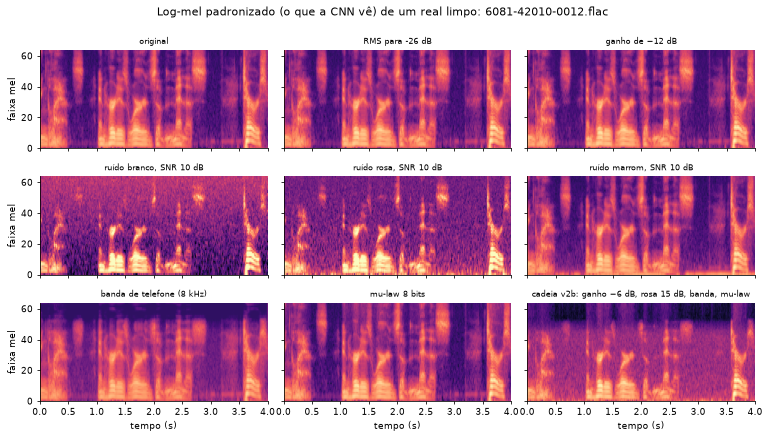

| operação                                           |   diferença média para o original (desvios-padrão) |
|:---------------------------------------------------|---------------------------------------------------:|
| original                                           |                                              0     |
| RMS para -26 dB                                    |                                              0.002 |
| ganho de −12 dB                                    |                                              0.016 |
| ruído branco, SNR 10 dB                            |                                              0.686 |
| ruído rosa, SNR 10 dB                              |                                              0.558 |
| ruído marrom, SNR 10 dB                            |                                              0.122 |
| banda de telefone (8 kHz)                          |                                              0.384 |
| mu-law 8 bits                                      |                                              0.064 |
| cadeia v2b: ganho −6 dB, rosa 15 dB, banda, mu-law |                                              0.54  |

In [6]:
ex = df[(df.split == "val") & (df.source_dataset == "librispeech") & (df.duration_s >= 4.5)].sample(
    1, random_state=SEED).iloc[0]
x0 = AudioDataset([ex.path], [0], [ex.sample_rate], [ex.duration_s], crop_s=CROP_S,
                  target_sr=SAMPLE_RATE, mode="center")[0][0]
logmel_cpu = LogMelPadronizado(SAMPLE_RATE, N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS)


def cadeia_v2b(x):
    # Um exemplo da cadeia completa do v2b, com valores fixos para a figura.
    return mu_law(limitar_banda(adicionar_ruido(aplicar_ganho(x, -6), 15, 1), SAMPLE_RATE, SR_BANDA))


torch.manual_seed(SEED)
OPERACOES = [
    ("original", lambda x: x),
    (f"RMS para {RMS_ALVO_DB:.0f} dB", lambda x: normalizar_rms(x, RMS_ALVO_DB)),
    ("ganho de −12 dB", lambda x: aplicar_ganho(x, -12)),
    ("ruído branco, SNR 10 dB", lambda x: adicionar_ruido(x, 10, 0)),
    ("ruído rosa, SNR 10 dB", lambda x: adicionar_ruido(x, 10, 1)),
    ("ruído marrom, SNR 10 dB", lambda x: adicionar_ruido(x, 10, 2)),
    ("banda de telefone (8 kHz)", lambda x: limitar_banda(x, SAMPLE_RATE, SR_BANDA)),
    ("mu-law 8 bits", lambda x: mu_law(x, MULAW_CANAIS)),
    ("cadeia v2b: ganho −6 dB, rosa 15 dB, banda, mu-law", cadeia_v2b),
]
ONDAS_AUG = {nome: f(x0.clone()) for nome, f in OPERACOES}
IMGS = {nome: logmel_cpu(w.unsqueeze(0))[0, 0].numpy() for nome, w in ONDAS_AUG.items()}

fig, axes = plt.subplots(3, 3, figsize=(11, 6.2), sharex=True, sharey=True, dpi=70)   # dpi menor: imagem pesada
for ax, (nome, img) in zip(axes.flat, IMGS.items()):
    ax.imshow(img, origin="lower", aspect="auto", cmap="magma", vmin=-2.5, vmax=3, extent=[0, CROP_S, 0, N_MELS])
    ax.set_title(nome, fontsize=8.5)
    ax.grid(False)
for ax in axes[:, 0]:
    ax.set_ylabel("faixa mel")
for ax in axes[-1]:
    ax.set_xlabel("tempo (s)")
plt.suptitle(f"Log-mel padronizado (o que a CNN vê) de um real limpo: {Path(ex.path).name}", y=1.0)
plt.tight_layout()
plt.show()

orig = IMGS["original"]
TAB_DIF = pd.DataFrame([{"operação": nome, "diferença média para o original (desvios-padrão)":
                         round(float(np.abs(img - orig).mean()), 3)} for nome, img in IMGS.items()])
show_md(TAB_DIF, index=False)

**Conclusão:** como previsto, **RMS e ganho deixam a imagem praticamente igual** à original (diferença próxima de zero): a padronização por exemplo já remove o volume. Por isso esperamos que o **v2a quase não mude nada** (é o experimento de controle). As degradações do v2b mudam a imagem de verdade: o ruído branco "enche" as pausas e as faixas altas, o rosa e o marrom enchem os graves, a banda de telefone apaga tudo acima de ~4 kHz (as faixas mel de cima ficam vazias) e o mu-law adiciona um chiado fraco nas pausas.

**Ouvir.** Seis reprodutores (o limite do formato do notebook): o original e cinco versões degradadas.

> ⚠️ **Fora da trilha:** `IPython.display.Audio` cria o reprodutor dentro do notebook.

In [7]:
for nome in ["original", "ruído branco, SNR 10 dB", "ruído marrom, SNR 10 dB", "banda de telefone (8 kHz)",
             "mu-law 8 bits", "cadeia v2b: ganho −6 dB, rosa 15 dB, banda, mu-law"]:
    display(Markdown(f"**{nome}**"))
    display(Audio(ONDAS_AUG[nome].numpy(), rate=SAMPLE_RATE))

**original**

**ruído branco, SNR 10 dB**

**ruído marrom, SNR 10 dB**

**banda de telefone (8 kHz)**

**mu-law 8 bits**

**cadeia v2b: ganho −6 dB, rosa 15 dB, banda, mu-law**

## 5. Análise exploratória: os reais do treino são mesmo "limpos"?

A EDA completa dos dados (desbalanceamento, duração, taxa de amostragem, volume) está na seção 5 da v1. Aqui fazemos só a análise nova: **testar a hipótese nos dados, antes de treinar**.

**O que faz:** para cada fonte e classe do treino/validação (até `EDA_POR_GRUPO` áudios) e para o dev_shift inteiro, mede a **faixa dinâmica** do recorte central de 4 s: a diferença, em dB, entre a energia dos 5% de quadros mais fortes e a dos 10% mais fracos.
**Por quê:** numa gravação limpa, as pausas são quase silêncio e essa diferença é grande; numa gravação com ruído de fundo, as pausas têm ruído e a diferença é pequena. Se a hipótese estiver certa, os **reais do treino** têm faixa dinâmica bem maior que os **reais do In-the-Wild (dev_shift)**.

> ⚠️ **Fora da trilha (faixa dinâmica):** é uma estimativa grosseira da relação sinal-ruído que não precisa saber onde está a fala. Função `faixa_dinamica_db` em `src/analysis.py`. Também usamos a AUC (seção 7 da v1) para medir se essa medida, sozinha, separa real de fake.

mediana da faixa dinâmica (dB),real,fake,AUC da faixa (fake = mais ruído)
grupo,,,
dev_shift · in_the_wild,32.900002,37.500000,0.375
treino/val · asvspoof2019_la,48.599998,48.400002,0.506
treino/val · codecfake_plus,32.799999,33.000000,0.522
treino/val · dfadd,31.299999,35.099998,0.299
treino/val · librispeech,35.299999,NaN,NaN
treino/val · shiftyspeech,37.500000,40.700001,0.463


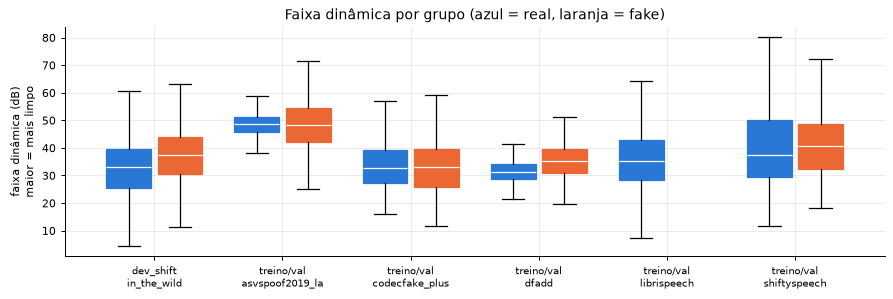

In [8]:
def medir_faixa(amostra):
    ds = AudioDataset(amostra.path, amostra.label, amostra.sample_rate, amostra.duration_s,
                      crop_s=CROP_S, target_sr=SAMPLE_RATE, mode="center")
    out = [faixa_dinamica_db(x) for x, _ in DataLoader(ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS)]
    return amostra.assign(faixa_db=torch.cat(out).numpy())


pool_eda = df[df.split.isin(["train", "val"])]
amostra_eda = pd.concat([g.sample(min(len(g), EDA_POR_GRUPO), random_state=SEED)
                         for _, g in pool_eda.groupby(["source_dataset", "label"])])
amostra_eda = medir_faixa(amostra_eda).assign(grupo=lambda d: "treino/val · " + d.source_dataset)
dev_faixa = medir_faixa(dev_df).assign(grupo="dev_shift · in_the_wild")
EDA = pd.concat([amostra_eda, dev_faixa], ignore_index=True)
EDA["classe"] = EDA["label"].map({0: "real", 1: "fake"})

TAB_FAIXA = EDA.pivot_table(index="grupo", columns="classe", values="faixa_db", aggfunc="median").round(1)
TAB_FAIXA = TAB_FAIXA.reindex(columns=["real", "fake"])
for grupo, g in EDA.groupby("grupo"):
    if g.label.nunique() == 2:
        a = roc_auc_score(g.label, -g.faixa_db)          # nota de fake = faixa MENOR (mais ruído)
        TAB_FAIXA.loc[grupo, "AUC da faixa (fake = mais ruído)"] = round(a, 3)
TAB_FAIXA.columns.name = "mediana da faixa dinâmica (dB)"
display(TAB_FAIXA)

fig, ax = plt.subplots(figsize=(10, 3.4))
grupos = list(TAB_FAIXA.index)
pos = np.arange(len(grupos))
for lab, cor, desl in [(0, REAL_C, -0.2), (1, FAKE_C, 0.2)]:
    dados = [EDA[(EDA.grupo == gname) & (EDA.label == lab)].faixa_db.values for gname in grupos]
    ok = [i for i, d in enumerate(dados) if len(d)]
    bp = ax.boxplot([dados[i] for i in ok], positions=pos[ok] + desl, widths=0.35, patch_artist=True,
                    showfliers=False, medianprops={"color": "white"})
    for bx in bp["boxes"]:
        bx.set(facecolor=cor, edgecolor=cor)
ax.set_xticks(pos, [gname.replace(" · ", "\n") for gname in grupos], fontsize=8)
ax.set_ylabel("faixa dinâmica (dB)\nmaior = mais limpo")
ax.set_title("Faixa dinâmica por grupo (azul = real, laranja = fake)")
plt.tight_layout()
plt.show()

**Conclusão:** a premissa da hipótese **não aparece nos dados**. Em geral, os reais do treino **não** são mais limpos que os do In-the-Wild. A mediana da faixa dinâmica dos reais do DFADD (31,3 dB), do CodecFake+ (32,8 dB) e do LibriSpeech (35,3 dB) é parecida com a dos reais do dev_shift (32,9 dB). Só o ASVspoof 2019 é bem mais limpo (48,6 dB), e nele reais e fakes são iguais (AUC 0,506).

Dois detalhes vão no sentido **contrário** à hipótese:
1. **No DFADD, o maior banco do treino, os fakes são mais limpos que os reais** (35,1 × 31,3 dB; AUC 0,299 para "fake = mais ruído", ou seja, 0,70 para "fake = mais limpo"). Se o modelo pegou algum atalho de limpeza, o mais provável seria "limpo = fake".
2. **No dev_shift também os fakes são mais limpos** (37,5 × 32,9 dB).

Então a limpeza, do jeito que medimos, não explica por que o modelo ordena o In-the-Wild ao contrário (ver 7.4, 7.8 e 8). Ressalva: a faixa dinâmica é uma medida grosseira e não capta gravação antiga, eco de sala ou compressão.

## 6. Treinamento

### 6.1 Amostragem balanceada (igual à v1)

**O que faz:** monta os grupos (classe, fonte, gerador) do treino e calcula quantos áudios de cada um entram por época, com a mesma regra da v1 (agora em `src/sampling.py`): 25 mil reais + 25 mil falsos por época, teto por fonte e por gerador, fila embaralhada por grupo.
**Por quê:** é a mesma amostragem do baseline, para que a única diferença entre os experimentos seja a augmentation. A explicação completa está na seção 6.1 da v1.

In [9]:
pool_tr, GRUPOS, COTAS, val_df = preparar_treino(df, HP)      # src/experimento.py
TAB_COTAS = pd.DataFrame([{"classe": "real" if l == 0 else "fake", "fonte": s, "no pool": len(GRUPOS[(l, s, g)]),
                           "por época": c} for (l, s, g), c in COTAS.items()])
resumo = TAB_COTAS.groupby(["classe", "fonte"])[["no pool", "por época"]].sum()
resumo["% da classe na época"] = (100 * resumo["por época"] / PER_CLASS_PER_EPOCH).round(1)
display(resumo)

val_loader = loader_validacao(val_df, HP)                       # recorte central, não persistente
logmel = LogMelPadronizado(SAMPLE_RATE, N_FFT, WIN_LENGTH, HOP_LENGTH, N_MELS).to(DEVICE)
N_FRAMES = int(CROP_S * SAMPLE_RATE) // HOP_LENGTH + 1
print(f"treino: pool de {fmt(len(pool_tr))} áudios | validação: {fmt(len(val_df))} áudios | "
      f"entrada da CNN: 1 × {N_MELS} × {N_FRAMES}")
print("composição da validação:", val_df.groupby("source_dataset").size().to_dict())

no pool  por época  % da classe na época
classe fonte                                                    
fake   asvspoof2019_la    45096       8086                  32.3
       codecfake_plus       743        743                   3.0
       dfadd             131700       8086                  32.3
       shiftyspeech       14121       8085                  32.3
real   asvspoof2019_la     5128       5128                  20.5
       codecfake_plus       702        702                   2.8
       dfadd              35745       7232                  28.9
       librispeech        22840       7231                  28.9
       shiftyspeech        4707       4707                  18.8

treino: pool de 260.782 áudios | validação: 51.189 áudios | entrada da CNN: 1 × 64 × 401
composição da validação: {'codecfake_plus': 352, 'dfadd': 40510, 'librispeech': 5699, 'shiftyspeech': 4628}


### 6.2 Escolha do checkpoint: EER média por fonte

**O problema na v1:** o checkpoint era escolhido pela EER da **validação inteira**. Só que **79% da validação é DFADD** (40.510 de 51.189 áudios). Na prática, escolhíamos o checkpoint que melhor separava o DFADD (EER 0,26%), sem olhar para o ShiftySpeech (7,8%) nem para o CodecFake+ (32,7%). A EER global de 1,3% escondia uma **média por fonte de 13,6%**.

**A regra nova:** calculamos a EER de **cada fonte** da validação separadamente e tiramos a **média simples**. Entram só as fontes que têm real **e** fake na validação: DFADD, ShiftySpeech e CodecFake+. O LibriSpeech fica de fora da média porque só tem reais (sem fake, não existe EER). O checkpoint guardado é o da **menor média**, e o early stopping para depois de `PATIENCE` épocas sem melhorar essa média. Assim, cada fonte pesa o mesmo na decisão.

Aplicamos a regra nova **também ao baseline retreinado (v1r)**, para a comparação com v2a e v2b ser justa: os três usam exatamente a mesma regra.

> ⚠️ **Fora da trilha:** a ideia de "early stopping guardando os melhores pesos" é da Aula 7; a métrica (EER média por fonte) é escolha nossa, pelo motivo acima. Código em `src/train.py` e `src/metrics.py`.

### 6.3 Os três experimentos

**O que faz:** mostra, para cada experimento, a probabilidade de cada operação de augmentation (0 = desligada). Todo o resto (dados, amostragem, modelo, otimizador, épocas, seed) é idêntico.

In [10]:
OPS = [("p_rms", "normalizar RMS"), ("p_ganho", "ganho"), ("p_ruido", "ruído"), ("p_banda", "banda 8 kHz"),
       ("p_mulaw", "mu-law"), ("p_mp3", "MP3/Opus")]
TAB_EXP = pd.DataFrame([{"experimento": exp, "descrição": cfg["descricao"],
                         **{nome: ("—" if k == "p_mp3" and not FFMPEG else cfg["aug"].get(k, 0))
                            for k, nome in OPS}}
                        for exp, cfg in EXPERIMENTOS.items()])
show_md(TAB_EXP, index=False)
if not FFMPEG:
    print("MP3/Opus: '—' = não aplicado, porque o ffmpeg não está instalado (ver seção 2).")

| experimento   | descrição                                                         |   normalizar RMS |   ganho |   ruído |   banda 8 kHz |   mu-law | MP3/Opus   |
|:--------------|:------------------------------------------------------------------|-----------------:|--------:|--------:|--------------:|---------:|:-----------|
| v1r           | baseline v1 retreinado; checkpoint pela EER média por fonte       |              0   |     0   |     0   |           0   |      0   | —          |
| v2a           | v1r + normalização de volume (RMS) e ganho aleatório              |              0.5 |     0.5 |     0   |           0   |      0   | —          |
| v2b           | v2a + ruído branco/colorido + limitação de banda (8 kHz) + mu-law |              0.5 |     0.5 |     0.3 |           0.3 |      0.3 | —          |

MP3/Opus: '—' = não aplicado, porque o ffmpeg não está instalado (ver seção 2).


### 6.4 Treino dos três experimentos

**O que faz:** para cada experimento, recria do zero o `Dataset` de treino (com a sua augmentation), a CNN (mesma seed de inicialização), o Adam e o sorteador de épocas (mesma seed, então as **mesmas épocas** nos três), e treina com o loop da Aula 6 (`src/experimento.py` e `src/train.py`). Se o experimento já foi treinado (por esta célula ou por `scripts/treinar_experimento.py`, num processo separado), com `REUSAR = True` ele só é lido do disco. Ao fim de cada época, avalia a validação (recorte central) e guarda o checkpoint quando a **EER média por fonte** melhora. Os checkpoints vão para `models/<experimento>_cnn.pt` e o histórico por época para `results/<experimento>_historico.csv`.
**Por quê:** com tudo igual, qualquer diferença entre os três vem da augmentation (e do acaso do treino na GPU, que não é 100% determinístico).

A CNN e a perda são as da v1: 4 blocos `Conv 3×3 → BatchNorm → ReLU → MaxPool 2×2` (16, 32, 64, 128 filtros), `Flatten → Dropout 0,3 → Linear(1)`, ~110 mil parâmetros, `BCEWithLogitsLoss` e Adam com taxa 0,001 (detalhes na seção 6.3 da v1).

In [11]:
HIST, TEMPO = {}, {}
for exp, cfg in EXPERIMENTOS.items():
    ckpt, hist_csv = caminho_ckpt(exp), caminho_hist(exp)
    if REUSAR and ckpt.exists() and hist_csv.exists():
        HIST[exp] = pd.read_csv(hist_csv)
        print(f"{exp}: checkpoint e histórico já existem ({ckpt}), não retreina (REUSAR = True)")
    else:                                    # o mesmo código que scripts/treinar_experimento.py usa
        HIST[exp] = treinar_experimento(exp, cfg, HP, pool_tr, GRUPOS, COTAS, val_df, val_loader, logmel,
                                        DEVICE, ckpt, hist_csv, VERSAO)
    TEMPO[exp] = HIST[exp]["segundos"].sum() / 60

v1r: checkpoint e histórico já existem (models\v1r_cnn.pt), não retreina (REUSAR = True)
v2a: checkpoint e histórico já existem (models\v2a_cnn.pt), não retreina (REUSAR = True)
v2b: checkpoint e histórico já existem (models\v2b_cnn.pt), não retreina (REUSAR = True)


### 6.5 Curvas de treino

**O que faz:** mostra, por época e por experimento, a EER média por fonte (a métrica que escolhe o checkpoint) e a EER global da validação (a métrica antiga), e marca a época escolhida.
**Por quê:** mostra se a augmentation atrasou o aprendizado (esperado: o treino fica mais difícil) e quanto as duas métricas discordam.

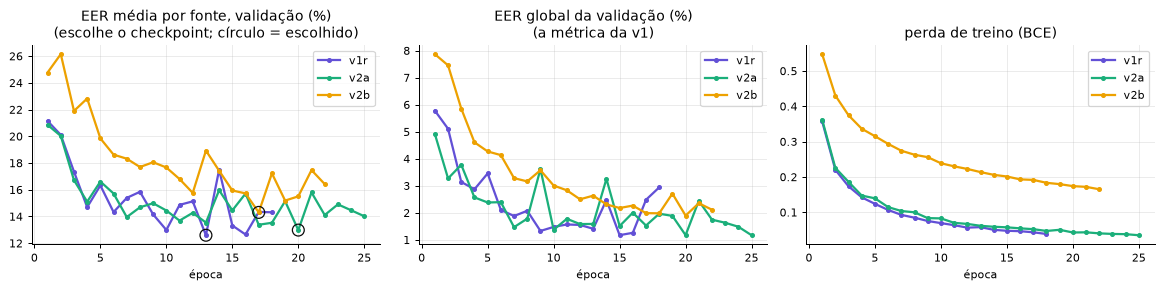

| experimento   |   épocas treinadas |   época escolhida | EER média por fonte (val)   | EER global (val) na mesma época   | EER val · codecfake_plus   | EER val · dfadd   | EER val · shiftyspeech   |   tempo de treino (min) |
|:--------------|-------------------:|------------------:|:----------------------------|:----------------------------------|:---------------------------|:------------------|:-------------------------|------------------------:|
| v1r           |                 18 |                13 | 12.59%                      | 1.41%                             | 28.96%                     | 0.22%             | 8.60%                    |                    23.2 |
| v2a           |                 25 |                20 | 12.98%                      | 1.17%                             | 30.97%                     | 0.18%             | 7.78%                    |                    33.5 |
| v2b           |                 22 |                17 | 14.30%                      | 1.98%                             | 30.14%                     | 0.67%             | 12.10%                   |                    34.2 |

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
linhas = []
for exp, h in HIST.items():
    cor = COR_EXP[exp]
    i = h["EER média por fonte (val)"].idxmin()
    axes[0].plot(h["época"], 100 * h["EER média por fonte (val)"], "o-", ms=3, color=cor, lw=1.8, label=exp)
    axes[0].scatter([h.loc[i, "época"]], [100 * h.loc[i, "EER média por fonte (val)"]], s=90,
                    facecolors="none", edgecolors="#0b0b0b", zorder=3)
    axes[1].plot(h["época"], 100 * h["EER global (val)"], "o-", ms=3, color=cor, lw=1.8, label=exp)
    axes[2].plot(h["época"], h["perda treino"], "o-", ms=3, color=cor, lw=1.8, label=exp)
    linhas.append({"experimento": exp, "épocas treinadas": len(h), "época escolhida": int(h.loc[i, "época"]),
                   "EER média por fonte (val)": f"{100 * h.loc[i, 'EER média por fonte (val)']:.2f}%",
                   "EER global (val) na mesma época": f"{100 * h.loc[i, 'EER global (val)']:.2f}%",
                   **{c.replace("EER val ", "EER val · "): f"{100 * h.loc[i, c]:.2f}%" for c in h.columns
                      if c.startswith("EER val ")},
                   "tempo de treino (min)": round(TEMPO[exp], 1)})
axes[0].set_title("EER média por fonte, validação (%)\n(escolhe o checkpoint; círculo = escolhido)")
axes[1].set_title("EER global da validação (%)\n(a métrica da v1)")
axes[2].set_title("perda de treino (BCE)")
for ax in axes:
    ax.set_xlabel("época")
    ax.legend()
plt.tight_layout()
plt.show()
TAB_TREINO = pd.DataFrame(linhas)
show_md(TAB_TREINO, index=False)

**Conclusão:** nenhum experimento chegou ao teto de 30 épocas. O early stopping parou o v1r na época 18 (melhor: 13), o v2a na 25 (melhor: 20) e o v2b na 22 (melhor: 17).

- **A augmentation deixou o treino mais difícil, como esperado.** Na época escolhida, a perda de treino do v2b é 0,19, contra 0,06 do v1r e 0,04 do v2a. Cada época do v2b levou ~93 s, contra ~77 a 80 s. Tempo total: 23,2 / 33,5 / 34,2 min.
- **Métrica que escolhe o checkpoint (EER média por fonte):** v1r 12,6%, v2a 13,0% e v2b 14,3%.

**Cuidado com essas diferenças.** De uma época para a outra, essa métrica oscila 1,0 a 1,6 ponto percentual (desvio-padrão nas épocas ao redor da escolhida). No CodecFake+, que tem só 352 áudios na validação, oscila 2 a 2,6 pontos. Portanto, v1r × v2a é ruído. O v2b ficar ~1,5 ponto pior está no limite do ruído e vem sobretudo do ShiftySpeech (8,6% → 12,1%). A EER global (1,2% a 2,0%) continua dominada pelo DFADD e diz pouco.

## 7. Avaliação

### 7.1 Métricas, limiar e avaliação por janelas

**Métricas principais: AUC e EER.** Elas **não dependem de limiar** nem da proporção real/fake, então são as que usamos para comparar versões e bancos. AUC: chance de um fake sorteado receber nota maior que um real sorteado (0,5 = chute, 1 = perfeito). EER: o erro no ponto em que falso alarme e fakes que escapam são iguais (0% = perfeito, 50% = chute). Definições completas na seção 7.1 da v1.

**Métricas com limiar: recall de fake e taxa de falso alarme.** Elas precisam de um limiar de decisão. Como na v1, o limiar é o da **EER na validação inteira**, escolhido na validação e fixado antes de olhar dev_shift e teste. Reportamos o limiar de cada experimento e o **falso alarme no CORAA** (só vozes reais em pt-BR).

**Por que o limiar de 0,039 da v1 era um problema:** ele foi fixado numa validação quase toda DFADD, em que os reais limpos recebem nota de fake quase zero, então bastava uma voz real um pouco diferente (ruído, outro microfone) passar de 3,9% de "chance de fake" para ser acusada, e foi isso que gerou 41,6% de falso alarme no CORAA.

**Avaliação por janelas deslizantes.** Na v1, o teste via só os 4 s do meio de cada áudio. Agora cada áudio é cortado em **janelas de 4 s com passo de 2 s** (a última janela termina no fim do áudio, para cobrir tudo), o modelo dá um logit para cada janela e a nota do áudio é a **média dos logits**. Reportamos as duas formas (janelas e recorte central) lado a lado; a principal passa a ser a de janelas. Cada forma tem o seu limiar (o da EER na validação avaliada da mesma forma).

> ⚠️ **Fora da trilha (janelas deslizantes e média dos logits):** o logit é a saída da CNN antes da sigmoide. Tirar a média dos logits (e não das probabilidades) evita que uma janela muito confiante domine e é a forma usual de juntar várias decisões do mesmo modelo. Código em `src/train.py` (`prever_janelas`).

### 7.2 Notas de todos os conjuntos (teste final: uma vez por experimento)

**O que faz:** carrega os três checkpoints e calcula a nota (logit) de cada áudio, nas duas formas (janelas e central), para: a validação inteira, o dev_shift inteiro e a amostra do teste final (até `TEST_MAX_PER_CLASS` áudios por classe e banco, sorteados com a seed 42, como na v1; no In-the-Wild, só a parte `test_final`). As notas são salvas em `results/<experimento>_notas_<conjunto>.parquet`; com `REUSAR = True`, rodar de novo **lê** as notas em vez de recalcular, então o teste final de cada experimento é calculado **uma única vez**.
**Por quê:** uma única passada, com os modelos congelados, garante que nenhum resultado de teste influenciou decisão nenhuma.

In [13]:
TESTES = ["in_the_wild", "llamapartialspoof", "brspeech_df", "asvspoof2019_la", "asvspoof2021_df", "coraa"]
TIPO = {"in_the_wild": "principal (só test_final)", "llamapartialspoof": "principal", "brspeech_df": "principal (pt)",
        "asvspoof2019_la": "secundário", "asvspoof2021_df": "secundário", "coraa": "falso alarme pt-BR"}
teste_full = df[(df.split == "test") & (df.eval_subset == "test_final")]
partes = []
for src in TESTES:
    for lab in (0, 1):
        g = teste_full[(teste_full.source_dataset == src) & (teste_full.label == lab)]
        if len(g):
            partes.append(g.sample(min(len(g), TEST_MAX_PER_CLASS), random_state=SEED))
teste_df = pd.concat(partes).reset_index(drop=True)
TAM = teste_df.groupby("source_dataset")["label"].agg(real=lambda s: int((s == 0).sum()),
                                                     fake=lambda s: int((s == 1).sum())).reindex(TESTES)
TAM["no banco (test_final)"] = teste_full.groupby("source_dataset").size().reindex(TESTES)
TAM.insert(0, "tipo", [TIPO[s] for s in TESTES])
display(TAM)

N_JANELA, N_PASSO = int(JANELA_S * SAMPLE_RATE), int(PASSO_S * SAMPLE_RATE)
COLS_NOTAS = ["path", "source_dataset", "label", "generator", "fake_type", "speaker_id", "duration_s"]


def carregar_modelo(exp):
    ck = torch.load(caminho_ckpt(exp), map_location=DEVICE)
    m = CNNPequena(N_MELS, N_FRAMES, DROPOUT).to(DEVICE)
    m.load_state_dict(ck["model_state"])
    m.eval()
    return m, ck


def notas(exp, conjunto, amostra):
    # Logit por áudio (janelas e central). Lê do disco se já foi calculado com a mesma amostra.
    arq = caminho_notas(exp, conjunto)
    if REUSAR and arq.exists():
        salvo = pd.read_parquet(arq)
        if salvo["path"].tolist() == amostra["path"].tolist():
            return salvo, False
    ds = AudioInteiroDataset(amostra.path, amostra.label, target_sr=SAMPLE_RATE, min_s=JANELA_S)
    dl = DataLoader(ds, batch_size=AUDIOS_POR_LOTE_JANELAS, shuffle=False, num_workers=NUM_WORKERS,
                    collate_fn=juntar_lista)
    y, z_jan, z_cen, n_jan = prever_janelas(MODELOS[exp], logmel, dl, DEVICE, N_JANELA, N_PASSO)
    assert (y == amostra.label.values).all()
    out = amostra[COLS_NOTAS].reset_index(drop=True).assign(z_janelas=z_jan, z_central=z_cen, n_janelas=n_jan)
    out.to_parquet(arq, index=False)
    return out, True


MODELOS, CKPTS, NOTAS = {}, {}, {}
CONJUNTOS = {"val": val_df, "dev_shift": dev_df, "teste": teste_df}
for exp in EXPERIMENTOS:
    MODELOS[exp], CKPTS[exp] = carregar_modelo(exp)
    for conjunto, amostra in CONJUNTOS.items():
        t0 = time.time()
        NOTAS[(exp, conjunto)], novo = notas(exp, conjunto, amostra)
        print(f"{exp} · {conjunto}: {fmt(len(amostra))} áudios, "
              + (f"calculado em {(time.time() - t0) / 60:.1f} min" if novo else "lido do disco (já calculado)"))
print(f"janelas por áudio no teste: média {NOTAS[(exp, 'teste')].n_janelas.mean():.1f}, "
      f"máximo {NOTAS[(exp, 'teste')].n_janelas.max()}")

,tipo,real,fake,no banco (test_final)
source_dataset,,,,
in_the_wild,principal (só test_final),5000,5000,21165
llamapartialspoof,principal,5000,5000,140616
brspeech_df,principal (pt),1320,5000,7907
asvspoof2019_la,secundário,5000,5000,71237
asvspoof2021_df,secundário,5000,5000,152955
coraa,falso alarme pt-BR,5000,0,12350


v1r · val: 51.189 áudios, lido do disco (já calculado)
v1r · dev_shift: 10.614 áudios, lido do disco (já calculado)
v1r · teste: 51.320 áudios, lido do disco (já calculado)
v2a · val: 51.189 áudios, lido do disco (já calculado)
v2a · dev_shift: 10.614 áudios, lido do disco (já calculado)
v2a · teste: 51.320 áudios, lido do disco (já calculado)
v2b · val: 51.189 áudios, lido do disco (já calculado)
v2b · dev_shift: 10.614 áudios, lido do disco (já calculado)
v2b · teste: 51.320 áudios, lido do disco (já calculado)
janelas por áudio no teste: média 2.1, máximo 187


### 7.3 Validação e dev_shift (os conjuntos que decidem)

**O que faz:** fixa o limiar de cada experimento (EER na validação inteira, nas duas formas de avaliação) e mostra a EER por fonte da validação e as métricas do dev_shift.
**Por quê:** são os números que podemos usar para **escolher** entre v1r, v2a e v2b. O dev_shift é o que mais se parece com o mundo real.

In [14]:
MODOS = ["janelas", "central"]
LIMIAR = {}
linhas = []
for exp in EXPERIMENTOS:
    v = NOTAS[(exp, "val")]
    for modo in MODOS:
        LIMIAR[(exp, modo)] = eer_e_limiar(v.label.values, v[f"z_{modo}"].values)[1]
    media, por_fonte = eer_media_por_fonte(v.label.values, v.z_central.values, v.source_dataset.values)
    d = NOTAS[(exp, "dev_shift")]
    linha = {"experimento": exp, "limiar central (prob.)": round(float(sigmoide(LIMIAR[(exp, "central")])), 3),
             "limiar janelas (prob.)": round(float(sigmoide(LIMIAR[(exp, "janelas")])), 3),
             "val: EER global": eer_e_limiar(v.label.values, v.z_central.values)[0],
             "val: EER média por fonte": media, **{f"val: EER {s}": e for s, e in por_fonte.items()}}
    for modo in MODOS:
        m = metricas(d.label.values, d[f"z_{modo}"].values, LIMIAR[(exp, modo)])
        linha.update({f"dev_shift ({modo}): AUC": m["AUC"], f"dev_shift ({modo}): EER": m["EER"],
                      f"dev_shift ({modo}): falso alarme": m["falso alarme"],
                      f"dev_shift ({modo}): recall fake": m["recall fake"]})
    linhas.append(linha)
TAB_DEC = pd.DataFrame(linhas).set_index("experimento")
vis = TAB_DEC.T.astype(object)
for i in vis.index:
    if "AUC" in i:
        vis.loc[i] = vis.loc[i].map(lambda v: f"{v:.3f}")
    elif "limiar" not in i:
        vis.loc[i] = vis.loc[i].map(lambda v: "—" if pd.isna(v) else f"{100 * v:.1f}%")
display(vis)
print("A v1 original tinha limiar 0,039 e, na validação, EER global 1,29% e EER média por fonte 13,6%.")

experimento,v1r,v2a,v2b
limiar central (prob.),0.609,0.094,0.789
limiar janelas (prob.),0.603,0.098,0.756
val: EER global,1.4%,1.1%,2.0%
val: EER média por fonte,12.5%,12.9%,14.2%
val: EER codecfake_plus,29.0%,31.0%,30.1%
val: EER dfadd,0.2%,0.2%,0.7%
val: EER shiftyspeech,8.3%,7.4%,11.8%
dev_shift (janelas): AUC,0.325,0.386,0.389
dev_shift (janelas): EER,63.7%,58.1%,57.0%
dev_shift (janelas): falso alarme,77.7%,71.5%,67.2%


A v1 original tinha limiar 0,039 e, na validação, EER global 1,29% e EER média por fonte 13,6%.


**Conclusão:**
- **Os limiares são muito diferentes:** 0,603 (v1r), 0,098 (v2a) e 0,756 (v2b), em probabilidade. Os três modelos separam a validação quase igual, mas dão notas em escalas diferentes. Por isso **recall e falso alarme não são comparáveis diretamente entre experimentos**: parte da diferença é só onde o limiar caiu. Para comparar quem separa melhor, use AUC e EER.
- **Validação por fonte:** v1r e v2a empatam. O v2b piora no ShiftySpeech (EER 8,3% → 11,8%; a AUC cai 0,033, mais do que a incerteza da amostra) e empata no CodecFake+ (29% a 31%, dentro do ruído com 352 áudios).
- **dev_shift:** a AUC continua **abaixo de 0,5 nos três** (0,325 / 0,386 / 0,389), ou seja, o modelo continua ordenando ao contrário as vozes de internet. v2a e v2b sobem ~0,06 sobre o v1r e empatam entre si (+0,002).
- **Esse ganho é real?** Um bootstrap reamostrando os 16 locutores dá v2a − v1r = +0,065 [+0,035; +0,113] e v2b − v1r = +0,067 [−0,029; +0,187]. Mas esse intervalo mede só a incerteza da amostra de áudios, **não** o acaso do treino, e há só uma execução por experimento. O v2a é um controle: o volume quase não muda a entrada da CNN (seção 4). Só que a augmentation usa o mesmo sorteador do recorte aleatório, então, a partir do primeiro lote, o v2a também vê **outros trechos de 4 s** que o v1r. Na prática, é uma segunda execução com outra sorte. Se ela moveu o dev_shift em 0,065, **uma diferença desse tamanho está ao alcance do acaso do treino**, e o ruído do v2b não trouxe nada além disso.
- **Pela regra do jogo (validação + dev_shift), nenhum experimento é claramente melhor.** O v2a tem a melhor validação (empatado com o v1r) e empata com o v2b no dev_shift. O v2b tem a pior validação.

### 7.4 Teste de estresse na validação: o modelo acusa reais "sujos"?

**O que faz:** pega até `ESTRESSE_POR_FONTE` áudios por classe de cada fonte da validação e aplica, a **todos** (reais e falsos), uma degradação fixa: ruído branco a 20 dB e a 10 dB, ruído marrom a 10 dB, banda de telefone e mu-law. Mede o falso alarme (reais acusados, no limiar do recorte central) e a AUC em cada condição.
**Por quê:** é o teste direto da hipótese, **sem usar o teste**. Se o modelo aprendeu "limpo = real", degradar um real limpo deve fazê-lo parecer fake (o falso alarme sobe). Ressalva: o v2b viu essas degradações no treino, então para ele isso não é surpresa; a prova de que ele generaliza é o dev_shift.

2.852 áudios da validação (1.664 reais, 1.188 fakes)


falso alarme                  AUC              
experimento                        v1r    v2a    v2b    v1r    v2a    v2b
condição                                                                 
limpo                            0.041  0.039  0.051  0.965  0.965  0.961
ruído branco 20 dB               0.005  0.136  0.105  0.502  0.559  0.845
ruído branco 10 dB               0.031  0.582  0.071  0.487  0.499  0.776
ruído marrom 10 dB               0.016  0.008  0.070  0.898  0.858  0.950
banda de telefone (8 kHz)        0.083  0.033  0.062  0.794  0.838  0.939
mu-law 8 bits                    0.075  0.037  0.099  0.887  0.890  0.949

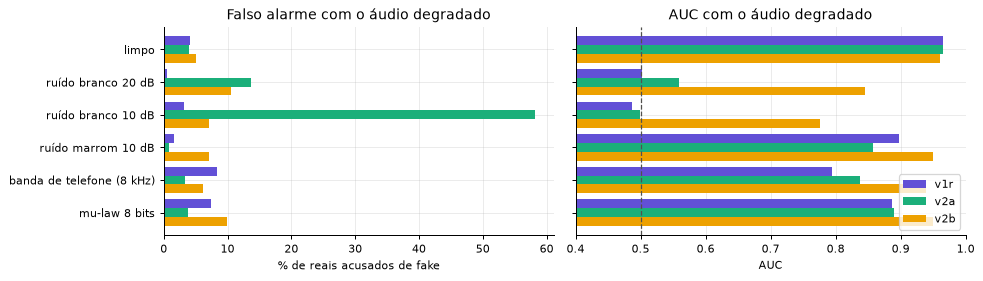

In [15]:
est = pd.concat([g.sample(min(len(g), ESTRESSE_POR_FONTE), random_state=SEED)
                 for _, g in val_df.groupby(["source_dataset", "label"])]).reset_index(drop=True)
CONDICOES = {"limpo": None,
             "ruído branco 20 dB": partial(adicionar_ruido, snr_db=20, expoente=0),
             "ruído branco 10 dB": partial(adicionar_ruido, snr_db=10, expoente=0),
             "ruído marrom 10 dB": partial(adicionar_ruido, snr_db=10, expoente=2),
             "banda de telefone (8 kHz)": partial(limitar_banda, sr=SAMPLE_RATE, sr_baixo=SR_BANDA),
             "mu-law 8 bits": partial(mu_law, canais=MULAW_CANAIS)}
linhas = []
for cond, f in CONDICOES.items():
    ds = AudioDataset(est.path, est.label, est.sample_rate, est.duration_s, crop_s=CROP_S,
                      target_sr=SAMPLE_RATE, mode="center", augment=f)
    dl = DataLoader(ds, batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, generator=torch.Generator().manual_seed(SEED))
    zs = {exp: [] for exp in EXPERIMENTOS}
    with torch.no_grad():
        for xb, _ in dl:                           # as MESMAS ondas degradadas vão para os três modelos
            entrada = logmel(xb.to(DEVICE))
            for exp in EXPERIMENTOS:
                zs[exp].append(MODELOS[exp](entrada).cpu())
    for exp in EXPERIMENTOS:
        m = metricas(est.label.values, torch.cat(zs[exp]).numpy(), LIMIAR[(exp, "central")])
        linhas.append({"condição": cond, "experimento": exp, "AUC": m["AUC"], "falso alarme": m["falso alarme"],
                       "recall fake": m["recall fake"]})
TAB_EST = pd.DataFrame(linhas)
print(f"{fmt(len(est))} áudios da validação ({fmt((est.label == 0).sum())} reais, {fmt((est.label == 1).sum())} fakes)")
display(TAB_EST.pivot(index="condição", columns="experimento", values=["falso alarme", "AUC"])
        .reindex(list(CONDICOES)).round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.2), sharey=True)
y = np.arange(len(CONDICOES))
for k, exp in enumerate(EXPERIMENTOS):
    g = TAB_EST[TAB_EST.experimento == exp].set_index("condição").reindex(list(CONDICOES))
    axes[0].barh(y + (k - 1) * 0.27, 100 * g["falso alarme"], 0.27, color=COR_EXP[exp], label=exp)
    axes[1].barh(y + (k - 1) * 0.27, g["AUC"], 0.27, color=COR_EXP[exp], label=exp)
axes[0].set_yticks(y, list(CONDICOES))
axes[0].invert_yaxis()
axes[0].set_xlabel("% de reais acusados de fake")
axes[0].set_title("Falso alarme com o áudio degradado")
axes[1].set_xlabel("AUC")
axes[1].set_xlim(0.4, 1)
axes[1].axvline(0.5, color="#52514e", ls="--", lw=1)
axes[1].set_title("AUC com o áudio degradado")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()

**Conclusão:** para o v1r, o teste direto da hipótese deu o **contrário** do previsto. Se "limpo = real" fosse o atalho, sujar um real limpo faria ele parecer fake e o falso alarme subiria. Não subiu:
- Com ruído branco a 20 dB, o falso alarme do v1r **caiu** de 4,1% para 0,5%; a 10 dB, ficou em 3,1%. Enquanto isso, o recall de fake despencou de 87% para 1,3% e 2,6%, e a AUC foi para 0,49–0,50 (chute). Com ruído branco, o v1r chama **quase tudo de real**.
- Ruído marrom, banda de telefone e mu-law fazem o mesmo, mais fraco: falso alarme de 1,6% a 8,3% e recall caindo para 47% a 64%. Para o v1r, **ruído é pista de real**, não de fake, o que é coerente com a seção 5 (no DFADD, os fakes são os mais limpos).

Os outros dois experimentos:
- O **v2a** tem a AUC parecida com a do v1r (0,50 a 0,56 com ruído branco). Mas, com o limiar dele (0,098), o ruído branco a 10 dB gera 58% de falso alarme. A mesma degradação empurra para lados opostos em dois modelos que só diferem no acaso do treino: a resposta a uma degradação **nunca vista** é arbitrária.
- O **v2b**, que viu essas degradações no treino, recupera a AUC (0,78 a 0,95), com falso alarme de 5% a 11%. Isso era esperado, porque para ele não há surpresa. O que importa é se a robustez generaliza para o mundo real, e o dev_shift (7.3) diz que não.

### 7.5 Teste final por banco

**O que faz:** calcula AUC, EER, recall de fake e falso alarme de cada banco de teste, para cada experimento e nas duas formas de avaliação, junta com a validação, o dev_shift e o teste de estresse e salva tudo em `results/experiments.csv`.
**Por quê:** é a tabela que registra a v2 e que as próximas versões vão consultar. Lembrete: **nenhuma escolha é feita por esta tabela**; todos os experimentos são reportados.

In [16]:
HOJE = date.today().isoformat()


def linha_csv(exp, conjunto, banco, tipo, modo, g):
    m = metricas(g.label.values, g[f"z_{modo}"].values, LIMIAR[(exp, modo)])
    h = HIST[exp]
    i = h["EER média por fonte (val)"].idxmin()
    return {"versão": VERSAO, "experimento": exp, "descrição": EXPERIMENTOS[exp]["descricao"],
            "conjunto": conjunto, "banco": banco, "tipo": tipo, "avaliação": modo, **m,
            "limiar (prob.)": float(sigmoide(LIMIAR[(exp, modo)])), "limiar (logit)": LIMIAR[(exp, modo)],
            "época escolhida": int(h.loc[i, "época"]),
            "EER média por fonte val (checkpoint)": float(h.loc[i, "EER média por fonte (val)"]),
            "tempo de treino (min)": round(TEMPO[exp], 1), "data": HOJE}


REG = []
for exp in EXPERIMENTOS:
    for modo in MODOS:
        v = NOTAS[(exp, "val")]
        REG.append(linha_csv(exp, "validação", "todas as fontes", "validação", modo, v))
        for s, g in v.groupby("source_dataset"):
            REG.append(linha_csv(exp, "validação", s, "validação", modo, g))
        REG.append(linha_csv(exp, "dev_shift", "in_the_wild", "decisão entre versões", modo, NOTAS[(exp, "dev_shift")]))
        t = NOTAS[(exp, "teste")]
        for s in TESTES:
            REG.append(linha_csv(exp, "test_final", s, TIPO[s], modo, t[t.source_dataset == s]))
        ll = t[t.source_dataset == "llamapartialspoof"]
        for ft in ["full", "partial"]:
            REG.append(linha_csv(exp, "test_final", f"llamapartialspoof (só {ft})", "principal", modo,
                                 ll[(ll.label == 0) | (ll.fake_type == ft)]))
EXP_CSV = pd.DataFrame(REG)
est_csv = TAB_EST.assign(versão=VERSAO, conjunto="estresse (val)", banco=TAB_EST["condição"],
                         tipo="teste de estresse", avaliação="central", data=HOJE).drop(columns="condição")
EXP_CSV = pd.concat([EXP_CSV, est_csv], ignore_index=True)
EXP_CSV.to_csv(EXPERIMENTS_CSV, index=False)
print(f"salvo em {EXPERIMENTS_CSV} ({len(EXP_CSV)} linhas)")

principal = EXP_CSV[(EXP_CSV.conjunto.isin(["dev_shift", "test_final"])) & (EXP_CSV["avaliação"] == "janelas")
                    & (~EXP_CSV.banco.str.contains("só"))]
ORDEM_BANCOS = ["in_the_wild"] + TESTES
tab = principal.pivot_table(index=["conjunto", "banco"], columns="experimento",
                            values=["AUC", "EER", "falso alarme", "recall fake"], aggfunc="first")
tab = tab.reindex([("dev_shift", "in_the_wild")] + [("test_final", s) for s in TESTES])
vis = tab.copy()
for c in vis.columns:
    vis[c] = vis[c].map(lambda v: "—" if pd.isna(v) else (f"{v:.3f}" if c[0] == "AUC" else f"{100 * v:.1f}%"))
display(Markdown("**Avaliação por janelas (a principal).** AUC e EER não dependem de limiar; falso alarme e "
                 "recall usam o limiar da validação de cada experimento."))
display(vis)
for src in TESTES:
    pf = 100 * teste_full[teste_full.source_dataset == src].label.mean()
    if pf in (0, 100):
        print(f"⚠️ {src}: só tem {'reais' if pf == 0 else 'fakes'}; vale só a taxa de falso alarme.")

salvo em results\experiments.csv (102 linhas)


**Avaliação por janelas (a principal).** AUC e EER não dependem de limiar; falso alarme e recall usam o limiar da validação de cada experimento.

AUC                  EER                \
experimento                     v1r    v2a    v2b    v1r    v2a    v2b   
conjunto   banco                                                         
dev_shift  in_the_wild        0.325  0.386  0.389  63.7%  58.1%  57.0%   
test_final in_the_wild        0.262  0.354  0.336  68.2%  59.3%  61.3%   
           llamapartialspoof  0.625  0.595  0.646  40.7%  43.3%  39.1%   
           brspeech_df        0.776  0.801  0.779  27.9%  27.5%  28.9%   
           asvspoof2019_la    0.936  0.936  0.986  12.3%  11.7%   5.6%   
           asvspoof2021_df    0.716  0.701  0.750  33.8%  34.8%  31.9%   
           coraa                  —      —      —      —      —      —   

                             falso alarme               recall fake         \
experimento                           v1r    v2a    v2b         v1r    v2a   
conjunto   banco                                                             
dev_shift  in_the_wild              77.7%  71.5%  67.2%       62.4%  61.5%   
test_final in_the_wild              86.3%  78.9%  72.7%       70.4%  62.8%   
           llamapartialspoof        53.6%  50.0%  34.4%       73.2%  63.2%   
           brspeech_df              30.3%   4.8%  34.7%       73.7%  53.9%   
           asvspoof2019_la           0.4%   0.0%   0.4%       70.1%  57.4%   
           asvspoof2021_df          33.7%  33.8%  37.2%       66.0%  62.2%   
           coraa                    34.9%  24.3%  29.8%           —      —   

                                     
experimento                     v2b  
conjunto   banco                     
dev_shift  in_the_wild        50.9%  
test_final in_the_wild        44.8%  
           llamapartialspoof  56.6%  
           brspeech_df        76.4%  
           asvspoof2019_la    78.9%  
           asvspoof2021_df    82.2%  
           coraa                  —

⚠️ coraa: só tem reais; vale só a taxa de falso alarme.


### 7.6 Comparação entre as versões

**O que faz:** um gráfico com a AUC (janelas) de cada experimento no dev_shift e em cada banco de teste, com a v1 original (recorte central) como referência em cinza, e outro com o falso alarme no dev_shift e no CORAA.
**Por quê:** mostra de relance se alguma mudança moveu os bancos que importam. Na v1 original, o In-the-Wild foi avaliado no banco inteiro (antes de existir o dev_shift), então a barra cinza do In-the-Wild aparece no teste e não no dev_shift.

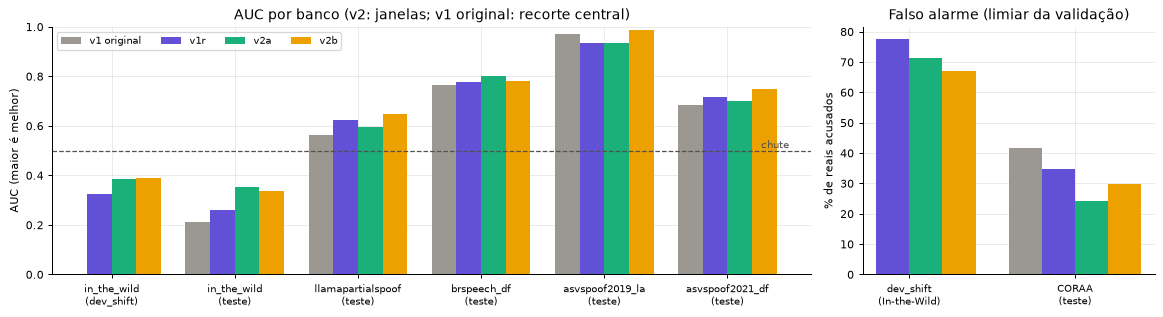

In [17]:
v1o = pd.read_csv("results/baseline_results.csv", index_col=0).rename(index={"asvspoof2019_la (eval)": "asvspoof2019_la"})
paineis = [("dev_shift", "in_the_wild")] + [("test_final", s) for s in TESTES if s != "coraa"]
rot = [f"{b}\n({'dev_shift' if c == 'dev_shift' else 'teste'})" for c, b in paineis]
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6), gridspec_kw={"width_ratios": [2.6, 1]})
x = np.arange(len(paineis))
series = ["v1 original"] + list(EXPERIMENTOS)
w = 0.8 / len(series)
for k, nome in enumerate(series):
    if nome == "v1 original":
        vals = [np.nan if c == "dev_shift" else v1o.loc[b, "AUC"] for c, b in paineis]
    else:
        g = principal[principal.experimento == nome].set_index(["conjunto", "banco"])
        vals = [g.loc[(c, b), "AUC"] for c, b in paineis]
    axes[0].bar(x + (k - (len(series) - 1) / 2) * w, vals, w, color=COR_EXP[nome], label=nome)
axes[0].axhline(0.5, color="#52514e", ls="--", lw=1)
axes[0].text(len(paineis) - 0.5, 0.51, "chute", color="#52514e", ha="right", fontsize=8)
axes[0].set_xticks(x, rot, fontsize=8)
axes[0].set_ylim(0, 1)
axes[0].set_ylabel("AUC (maior é melhor)")
axes[0].set_title("AUC por banco (v2: janelas; v1 original: recorte central)")
axes[0].legend(ncol=4, fontsize=8, loc="upper left")

fa = [("dev_shift", "in_the_wild", "dev_shift\n(In-the-Wild)"), ("test_final", "coraa", "CORAA\n(teste)")]
x2 = np.arange(len(fa))
for k, nome in enumerate(series):
    if nome == "v1 original":
        vals = [np.nan, v1o.loc["coraa", "falso alarme"]]
    else:
        g = principal[principal.experimento == nome].set_index(["conjunto", "banco"])
        vals = [g.loc[(c, b), "falso alarme"] for c, b, _ in fa]
    axes[1].bar(x2 + (k - (len(series) - 1) / 2) * w, 100 * np.asarray(vals, dtype=float), w, color=COR_EXP[nome])
axes[1].set_xticks(x2, [r for _, _, r in fa], fontsize=8)
axes[1].set_ylabel("% de reais acusados")
axes[1].set_title("Falso alarme (limiar da validação)")
plt.tight_layout()
plt.show()

### 7.7 Fakes parciais: janelas × recorte central no LlamaPartialSpoof

**O que faz:** no LlamaPartialSpoof, compara lado a lado a avaliação por janelas e pelo recorte central, separando os fakes completos (`full`) e os parciais (`partial`), sempre contra os mesmos reais.
**Por quê:** num fake parcial só alguns trechos são sintéticos, e o recorte central pode não pegar nenhum deles. As janelas olham o áudio inteiro. Se a média das janelas ajudar, a melhora deve aparecer mais nos parciais.

> ⚠️ **Fora da trilha:** avaliação por janelas deslizantes (ver 7.1).

In [18]:
ll = EXP_CSV[(EXP_CSV.conjunto == "test_final") & (EXP_CSV.banco.str.startswith("llamapartialspoof"))].copy()
ll["fakes"] = ll.banco.map({"llamapartialspoof": "todos", "llamapartialspoof (só full)": "só full",
                            "llamapartialspoof (só partial)": "só partial"})
TAB_LL = ll.pivot_table(index=["experimento", "fakes"], columns="avaliação", values=["AUC", "EER"], aggfunc="first")
TAB_LL = TAB_LL.reindex(columns=[("AUC", "central"), ("AUC", "janelas"), ("EER", "central"), ("EER", "janelas")])
TAB_LL[("AUC", "janelas − central")] = TAB_LL[("AUC", "janelas")] - TAB_LL[("AUC", "central")]
display(TAB_LL.round(3))
t = NOTAS[(list(EXPERIMENTOS)[0], "teste")]
print(f"LlamaPartialSpoof na amostra: {fmt((t[t.source_dataset == 'llamapartialspoof'].label == 0).sum())} reais; "
      f"janelas por áudio: média {t[t.source_dataset == 'llamapartialspoof'].n_janelas.mean():.1f}")

AUC             EER                       AUC
avaliação              central janelas central janelas janelas − central
experimento fakes                                                       
v1r         só full      0.673   0.697   0.369   0.356             0.024
            só partial   0.582   0.600   0.436   0.425             0.018
            todos        0.606   0.625   0.420   0.407             0.019
v2a         só full      0.622   0.646   0.420   0.399             0.024
            só partial   0.562   0.577   0.458   0.445             0.015
            todos        0.578   0.595   0.448   0.433             0.018
v2b         só full      0.684   0.695   0.350   0.340             0.012
            só partial   0.619   0.629   0.412   0.406             0.010
            todos        0.636   0.646   0.397   0.391             0.010

LlamaPartialSpoof na amostra: 5.000 reais; janelas por áudio: média 2.7


**Conclusão:** as janelas ajudam um pouco em todos os experimentos: +0,019 (v1r), +0,018 (v2a) e +0,010 (v2b) de AUC no total.

Mas, ao contrário do esperado, a melhora **não é maior nos fakes parciais** (+0,018 / +0,015 / +0,010) do que nos completos (+0,024 / +0,024 / +0,012). Os parciais continuam bem mais difíceis (AUC de 0,58 a 0,63) que os completos (0,65 a 0,70). Uma explicação provável: a **média** das janelas dilui o trecho falso no meio dos trechos reais. Usar a **maior nota** entre as janelas talvez funcione melhor nos parciais. Fica como ideia, mas só pode ser escolhida sem olhar o teste, e hoje não temos fakes parciais na validação.

Entre experimentos, o v2b vai melhor no LlamaPartialSpoof (0,646, contra 0,625 do v1r e 0,595 do v2a). A diferença é maior que a incerteza da amostra (bootstrap: v2b − v2a = +0,051 [+0,041; +0,060]), mas é teste: só reportamos, e isso não entra em decisão nenhuma.

### 7.8 Diagnóstico no dev_shift: quem são os reais acusados?

**O que faz:** divide os reais do dev_shift em três grupos iguais pela faixa dinâmica medida na seção 5 (mais ruidosos, intermediários, mais limpos) e mostra o falso alarme de cada experimento em cada grupo (avaliação por janelas).
**Por quê:** é a outra metade do teste da hipótese. Se "limpo = real" for o atalho, o falso alarme da v1r deve ser **maior nos reais mais ruidosos**, e uma augmentation que funcione deve **diminuir essa diferença**.

In [19]:
reais_dev = dev_faixa[dev_faixa.label == 0][["path", "faixa_db"]].copy()
reais_dev["grupo de ruído"] = pd.qcut(reais_dev.faixa_db, 3, labels=["mais ruidosos", "intermediários", "mais limpos"])
linhas = []
for exp in EXPERIMENTOS:
    d = NOTAS[(exp, "dev_shift")].merge(reais_dev, on="path")
    d["acusado"] = d.z_janelas >= LIMIAR[(exp, "janelas")]
    for grupo, g in d.groupby("grupo de ruído", observed=True):
        linhas.append({"experimento": exp, "grupo de ruído": grupo, "falso alarme": g.acusado.mean(),
                       "faixa dinâmica mediana (dB)": g.faixa_db.median(), "n reais": len(g)})
TAB_RUIDO = pd.DataFrame(linhas)
display(TAB_RUIDO.pivot(index="grupo de ruído", columns="experimento", values="falso alarme").mul(100).round(1)
        .reindex(["mais ruidosos", "intermediários", "mais limpos"])
        .rename_axis(columns="falso alarme (%) por experimento"))
display(TAB_RUIDO[TAB_RUIDO.experimento == list(EXPERIMENTOS)[0]][["grupo de ruído", "faixa dinâmica mediana (dB)", "n reais"]]
        .round(1).set_index("grupo de ruído"))

falso alarme (%) por experimento,v1r,v2a,v2b
grupo de ruído,,,
mais ruidosos,75.5,60.4,64.2
intermediários,76.7,72.1,70.6
mais limpos,81.0,82.0,66.6


,faixa dinâmica mediana (dB),n reais
grupo de ruído,,
mais ruidosos,23.299999,2878
intermediários,32.900002,2877
mais limpos,42.299999,2878


**Conclusão:** a outra metade do teste também **não confirma** a hipótese. No v1r, o falso alarme é **parecido nos três grupos** e até um pouco **maior nos reais mais limpos**: 75,5% nos mais ruidosos, 76,7% nos intermediários e 81,0% nos mais limpos. Se "limpo = real" fosse o atalho, os mais ruidosos seriam os mais acusados. Seja lá o que o modelo acusa nos reais de internet, não é o ruído de fundo (pelo menos não do jeito que a faixa dinâmica mede). O v2b deixou os três grupos parecidos (64% a 71%), mas ainda acusa dois terços dos reais.

**O que achamos ao investigar a AUC abaixo de 0,5.** A análise foi feita fora do notebook, com as notas salvas em `results/`, e só no dev_shift e na validação.
- **A inversão aparece dentro de cada locutor**, e não só quando misturamos locutores. No v1r, Winston Churchill tem AUC 0,02, Martin Luther King 0,04, Nelson Mandela 0,14 e Barack Obama 0,26. Os piores casos são figuras históricas: os reais são **gravações antigas** (fita, rádio, microfone da época) e os fakes são clones modernos. Gravação antiga é um tipo de "sujeira" que nenhuma das nossas augmentations imita.
- **A inversão é pior nos áudios curtos.** No v1r, a AUC é 0,25 em áudios de até 2 s e 0,44 nos acima de 4,75 s. No In-the-Wild, 68% dos reais têm menos de 4 s (contra 49% dos fakes) e são **repetidos** até completar 4 s. Na validação, os reais curtos não são acusados (0,7% de falso alarme abaixo de 2 s), então a repetição sozinha não explica a inversão, mas pode somar.
- São pistas, não provas: são só 16 locutores e uma execução por experimento.

## 8. Experimentos e conclusões

### 8.1 O que mudou, o que se esperava e o que aconteceu

| experimento | o que mudou | o que se esperava | o que aconteceu |
|:--|:--|:--|:--|
| **v1r** | só a regra do checkpoint (EER média por fonte, em vez da global) | números parecidos com a v1 | parecido: EER média por fonte 12,6% (v1: 13,6%) e In-the-Wild ainda invertido (AUC 0,262 no test_final). A v1 teve 0,211 no banco inteiro, com recorte central, então não é a mesma conta. CORAA 34,9% (v1: 41,6%, com outro limiar) |
| **v2a** | + normalização de volume (RMS) e ganho aleatório | quase nada (controle) | validação igual ao v1r; dev_shift +0,065 de AUC, In-the-Wild +0,09 e CORAA −10,6 pontos de falso alarme. Como a entrada quase não muda, atribuímos isso ao **acaso do treino** (a augmentation muda os sorteios dos recortes). Esse controle virou a nossa medida do ruído entre execuções |
| **v2b** | + ruído branco/rosa/marrom, banda de 8 kHz e mu-law | menos falso alarme no dev_shift e no CORAA e AUC maior no In-the-Wild | **robusto às degradações que viu** (teste de estresse: AUC de 0,78 a 0,95, contra 0,49 a 0,90 do v1r). **No dev_shift e no In-the-Wild, nada além do v2a:** 0,389 × 0,386 e 0,336 × 0,354. Validação um pouco pior (14,3%, puxada pelo ShiftySpeech). No teste, que só reportamos: melhor no ASVspoof 2019 (EER 11,7% → 5,6%), no ASVspoof 2021 DF (AUC 0,701 → 0,750) e no LlamaPartialSpoof (0,595 → 0,646); pior no BRSpeech-DF (0,801 → 0,779) e no CORAA (24,3% → 29,8% de falso alarme, com outro limiar) |

### 8.2 Números principais (janelas; teste final avaliado uma vez por experimento)

| conjunto | métrica | v1r | v2a | v2b |
|:--|:--|--:|--:|--:|
| validação | EER média por fonte (checkpoint) | 12,6% | 13,0% | 14,3% |
| validação | EER CodecFake+ / DFADD / ShiftySpeech (central) | 29,0 / 0,2 / 8,3% | 31,0 / 0,2 / 7,4% | 30,1 / 0,7 / 11,8% |
| **dev_shift** | AUC / EER | 0,325 / 63,7% | 0,386 / 58,1% | 0,389 / 57,0% |
| **dev_shift** | falso alarme | 77,7% | 71,5% | 67,2% |
| In-the-Wild (test_final) | AUC / EER | 0,262 / 68,2% | 0,354 / 59,3% | 0,336 / 61,3% |
| LlamaPartialSpoof | AUC janelas / central | 0,625 / 0,606 | 0,595 / 0,578 | 0,646 / 0,636 |
| BRSpeech-DF (pt) | AUC / EER | 0,776 / 27,9% | 0,801 / 27,5% | 0,779 / 28,9% |
| ASVspoof 2019 LA (secundário) | AUC / EER | 0,936 / 12,3% | 0,936 / 11,7% | 0,986 / 5,6% |
| ASVspoof 2021 DF (secundário) | AUC / EER | 0,716 / 33,8% | 0,701 / 34,8% | 0,750 / 31,9% |
| CORAA (só reais) | falso alarme | 34,9% | 24,3% | 29,8% |
| — | limiar (prob., EER da validação) | 0,603 | 0,098 | 0,756 |

### 8.3 A hipótese "limpo = real" se confirmou?

**Não.** Quatro evidências, todas tiradas de validação e dev_shift:
1. **Nos dados (seção 5):** os reais do treino não são mais limpos que os do In-the-Wild. No DFADD, os fakes é que são os mais limpos.
2. **No teste de estresse (7.4):** sujar um áudio faz o v1r chamar **mais** coisas de real, e não de fake.
3. **No dev_shift por grupo de ruído (7.8):** o v1r acusa os reais mais ruidosos tanto quanto os mais limpos (75,5% × 81,0%).
4. **Na comparação entre versões:** ensinar ruído e canal ruim (v2b) não melhorou o dev_shift além do controle (v2a). In-the-Wild: 0,262 → 0,354 → 0,336; dev_shift: 0,325 → 0,386 → 0,389; CORAA: 34,9% → 24,3% → 29,8% (este com limiares diferentes).

O problema do In-the-Wild é **outro**. As pistas (7.8) apontam para **gravações antigas** dos locutores históricos e para os **áudios curtos repetidos**. Mas são pistas, a testar na v3.

### 8.4 O que está dentro do ruído

- **Há uma execução por experimento**, e a métrica de validação oscila 1 a 1,6 ponto entre épocas vizinhas (2 a 2,6 pontos no CodecFake+). Diferenças de validação desse tamanho, como v1r × v2a e talvez v2a × v2b, não são resultado.
- **O controle v2a mostra o tamanho do acaso:** +0,065 de AUC no dev_shift e +0,09 no In-the-Wild sem mudar quase nada na entrada. Qualquer diferença dessa ordem no In-the-Wild ou no dev_shift **não está demonstrada**. Isso vale para v2a × v1r, v2b × v1r e v2b × v2a.
- **Os intervalos bootstrap** (por locutor no In-the-Wild, por áudio nos outros bancos) medem só a incerteza da amostra de teste, não a do treino. Eles subestimam a incerteza real.
- **Recall e falso alarme dependem do limiar,** que caiu em lugares muito diferentes (0,10 a 0,76). Exemplo: no BRSpeech-DF, o falso alarme vai de 30,3% para 4,8% e volta a 34,7%, enquanto a AUC quase não se move. Compare versões por AUC e EER.
- **Provavelmente real, mas não comprovado:** os ganhos do v2b no ASVspoof 2019, no ASVspoof 2021 DF e no LlamaPartialSpoof (~+0,05 de AUC sobre o v2a). Eles são maiores que o que o acaso moveu nesses bancos entre v1r e v2a (0,00 a −0,03) e vão na direção esperada (codec e canal). Já a robustez no teste de estresse é grande demais para ser acaso.

### 8.5 Regras do jogo

- O **teste final foi calculado uma única vez por experimento.** As notas ficam salvas em `results/<exp>_notas_teste.parquet`, e a 2ª execução do notebook só as leu do disco (`REUSAR = True`).
- **Os três experimentos estão reportados**, inclusive onde pioraram, em `results/experiments.csv` e em `docs/HISTORICO_VERSOES.md`.
- **A escolha entre versões usa só validação + dev_shift** (e o teste de estresse, que é feito na validação). Por esse critério, **nenhum experimento é claramente melhor**: as diferenças estão dentro do ruído, com o v2b um pouco pior na validação. Os ganhos do v2b no ASVspoof e no LlamaPartialSpoof são de teste e **não** podem justificar a escolha. A decisão sobre qual experimento serve de base para a v3 está nas dúvidas (8.7).
- Nenhuma nota foi invertida.

### 8.6 Conclusão em uma frase

**A augmentation de ruído e canal deixou o modelo robusto às degradações que ele viu, mas não consertou as vozes de internet (o dev_shift continua com AUC abaixo de 0,5, sem ganho além do controle), e a hipótese "limpo = real" não se confirmou: o atalho que o modelo usa no In-the-Wild é outro.**

### 8.7 Limitações e dúvidas

**Limitações:**
- Uma execução por experimento: não sabemos a variação entre seeds, só uma estimativa (o controle v2a e a oscilação entre épocas).
- O dev_shift tem só 16 locutores, só 18,7% de fakes e é dominado por Obama e Trump (6.570 dos 8.633 reais).
- A compressão MP3/Opus ficou de fora porque o `ffmpeg` não está instalado (seção 2).
- O In-the-Wild da v1 (banco inteiro, recorte central) e o da v2 (test_final, janelas) não são a mesma conta.
- A faixa dinâmica é uma medida grosseira de "limpeza".
- O CodecFake+ tem só 352 áudios na validação, então a EER dele oscila muito.
- A EER por fonte do histórico de treino e a recalculada na 7.3 diferem um pouco (ex.: ShiftySpeech 8,6% × 8,3% no v1r), porque as duas contas tiram o trecho central por caminhos diferentes (`AudioDataset` × `prever_janelas`). Isso não muda nenhuma conclusão.

**Dúvidas de decisão (não decididas aqui):**
1. **Qual experimento é a base da v3?** Por validação + dev_shift, empate. O v2b é robusto a ruído na validação degradada, mas um pouco pior na validação limpa. Sugestão: manter a augmentation do v2b como base, porque ela não prejudicou o dev_shift e protege contra degradações comuns. Mas é uma escolha do grupo, e não pode usar o teste como argumento.
2. **Repetir cada experimento com 2 ou 3 seeds** antes de comparar versões? Custa ~30 min por execução, mas é a única forma de separar efeito de acaso.
3. **O limiar** continua sendo o da EER da validação, que muda muito entre modelos. Vale fixá-lo de outra forma (por exemplo, no dev_shift)?
4. **Como agregar as janelas** (média, máximo), sem fakes parciais na validação para decidir?